<a href="https://colab.research.google.com/github/bsyeol/26AI_project/blob/main/final/FDS_StageB_TimeAware_Transformer_Ablation_Seed0_Resume.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FDS | Time-aware Transformer — temporal feature ablation (Seed 0)

**목적:** 짧은 관찰 기간에서 Transformer의 성능 개선 가능성을 검증한다. FraudTransformer의 시간 인코딩 아이디어를 참고하지만 GPT 사전학습 또는 원논문 재현은 아니다.

- 3개 실험군: Transformer (no time), Transformer + elapsed time, Transformer + Time2Vec. 동일한 32차원/4 heads/1 layer/FFN 64/dropout 0.1 backbone을 사용하고 파라미터 수를 맞추지 않는다.
- 경과 시간: 각 3시간 bin에서 가장 최근 **해당 window 내부**의 거래 발생 bin까지의 거리. 현재 bin 제외, 첫 거래 이전 및 padding은 unknown. 실제 분·초 거래 간격이 아니다.
- 동일한 원본 7개 history 특징, 현재 거래 7개 특징 + 32차원 embedding, 데이터 분할 및 분류기 유지. Mask 미적용도 기존 조건 유지.
- 1/2/7일을 먼저 실행 (27회), 14/30일 추가 (18회). Seed 0, Original, Test 미사용. RUN_LONG=False로 긴 기간만 연기할 수 있다. 각 arm/기간별 자동 재개. 원본 결과는 읽기 전용.
- 짧은 기간 성능 개선은 가설이다. Time2Vec 자체의 이점은 elapsed time 대조군과 비교한다. 학습 가능한 파라미터 차이는 남는다.
- Colab GPU L4/A100, 기존 패키지 및 Secrets. 그래프 영어 PNG/SVG. 실제 A100/L4 전체 실행은 미검증.
- 참고: https://arxiv.org/abs/1907.05321 (Time2Vec), https://arxiv.org/abs/2509.23712 (FraudTransformer).


In [1]:
# 1. Colab 설치: 기존 실험 버전 유지
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError
packages={'tabpfn':'10.2.0','lightgbm':'4.7.0','pyarrow':'26.0.1'}
need=[]
for p,v in packages.items():
    try: installed=version(p)
    except PackageNotFoundError: installed=None
    if installed!=v: need.append(f'{p}=={v}')
if need: subprocess.check_call([sys.executable,'-m','pip','install','-q',*need])
# 이미 import된 패키지가 변경됐다면 런타임 재시작

In [2]:
# 2. 환경/설정 — GRU 원본 읽기 전용, Transformer 별도 저장
from google.colab import drive, userdata
import os, json, gc, time, hashlib, inspect, platform, random, uuid
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
from torch import nn
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, precision_recall_curve, auc, roc_curve
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from tabpfn.finetuning.finetuned_classifier import FinetunedTabPFNClassifier
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/26-2_AI_project/processed/full')
SMOKE=False  # 기존 본 실험과 동일
RUN_DAYS=[1,2,7,14,30]
RUN_SEEDS=[0]
ALLOW_HARDWARE_CHANGE=True  # CPU/GPU 차이만 허용; 시간은 직접 비교 금지
RATIO='Original'  # 원본 비율 고정
WINDOW_DAYS=list(range(91))  # 0: baseline, 1~90: 매일 GRU
SEEDS=[0,1,2,3,4]
EVAL_NEG_FRAC=1.0  # 본 실험은 전수 평가; 빠른 예비 실험만 .2 (가중 지표)
TUNE_N=50000
TARGET_FPR=.001
REVIEW_TARGET_RECALL=.30  # 동일 Recall 비교용 목표: 30%, 필요 시 변경 (운영 기준 아님)
assert 0 < REVIEW_TARGET_RECALL <= 1
LATENCY_LIMIT=100.
LATENCY_REPEATS=20; LATENCY_WARMUPS=3
HIDDEN=32; GRU_EPOCHS=20; GRU_PATIENCE=3; GRU_LR=1e-3; GRU_BATCH=256
FT_EPOCHS=10; FT_LR=1e-5; FT_EPISODE=4096; FT_PATIENCE=3  # Original의 희소 양성 고려
FT_TRAIN_EST=1; FINAL_EST=4; FT_VAL_EST=1
PRED_BATCH=4096
MAX_TREES=2000; LGB_PATIENCE=50
THREADS=min(8,len(os.sched_getaffinity(0)))
MODELS=['LightGBM','TabPFN 3.5','TabPFN 3.5 FT']
assert torch.cuda.is_available(), 'GPU 런타임 필요'
assert hasattr(ModelVersion,'V3_5'), 'TabPFN 3.5 버전 필요'
# 라이브러리 버전별 API 불일치를 초기에 확인 (모델 자동 대체 금지)
ft_args=set(inspect.signature(FinetunedTabPFNClassifier).parameters)
required={'model_version','extra_classifier_kwargs','epochs','learning_rate','n_finetune_ctx_plus_query_samples','n_estimators_finetune','n_estimators_validation','n_estimators_final_inference','early_stopping_patience','eval_metric','random_state','use_activation_checkpointing','validation_split_ratio','device'}
assert required <= ft_args, f'Fine-tuning API 불일치: {required-ft_args}'
assert {'X_val','y_val'} <= set(inspect.signature(FinetunedTabPFNClassifier.fit).parameters), '외부 validation 지원 API 필요'
if not os.environ.get('TABPFN_TOKEN'):
    for k in ('TABPFN_TOKEN','TABPFN_API_KEY'):
        try: token=userdata.get(k)
        except Exception: continue
        if token: os.environ['TABPFN_TOKEN']=token; del token; break
assert os.environ.get('TABPFN_TOKEN'), 'Colab Secrets 인증 키 확인'
assert not SMOKE, '기존 GRU와 비교하는 본 예비 실험은 SMOKE=False 유지'
assert RATIO=='Original' and 0<EVAL_NEG_FRAC<=1
GRU_OUT=ROOT/'gru_tabpfn35_original_daily_v2_full'
EXP_OUT=ROOT/'timeaware_transformer_ablation_tabpfn35_original_seed0_v1_full'
OUT=EXP_OUT  # activate_arm() selects separate subfolder before running
MATCHED_OUT=ROOT/'transformer_matched_tabpfn35_original_seed0_v1_full'
SIGMA_OUT=ROOT/'sigma_fds_native_width_torchscan_tabpfn35_original_seed0_v1_full'
ARMS={'none':'Transformer (no time)','scalar':'Transformer + elapsed time','time2vec':'Transformer + Time2Vec'}
ARM='none'
TIME_DIM=8
RUN_LONG=True  # False: complete 1,2,7 days only; change to True to resume long phase
SHORT_DAYS=[1,2,7]; LONG_DAYS=[14,30]
TF_HEADS=4; TF_LAYERS=1; TF_FF=64; TF_DROPOUT=.1
assert HIDDEN % TF_HEADS == 0
OUT.mkdir(parents=True,exist_ok=True)
S=json.loads((ROOT/'settings.json').read_text(encoding='utf-8'))
BASE=S['BASE_FEATURES']; CAT=S['CATEGORICAL_FEATURES']; LABEL=S['LABEL']; USER=S['USER']; CAT_IDX=[BASE.index(c) for c in CAT]
assert len(BASE)==7 and set(SEEDS)<=set(S['SEEDS'])
assert '거래금액_로그' in BASE and '매체구분' in CAT
DEVICE='cuda'; SESSION=uuid.uuid4().hex[:12]
ENV=dict(gpu=torch.cuda.get_device_name(0),vram=int(torch.cuda.get_device_properties(0).total_memory),cpu=next((x.split(':',1)[1].strip() for x in Path('/proc/cpuinfo').read_text().splitlines() if x.startswith('model name')),platform.processor()),threads=THREADS,python=platform.python_version(),cuda=torch.version.cuda,versions={p:version(p) for p in ['tabpfn','torch','lightgbm','numpy','pandas','scikit-learn','pyarrow']})
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''): h.update(b)
    return h.hexdigest()
def write_json(p,obj):
    tmp=p.with_suffix(p.suffix+'.tmp'); tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8'); os.replace(tmp,p)
def write_csv(p,obj):
    tmp=p.with_suffix(p.suffix+'.tmp'); obj.to_csv(tmp,index=False); os.replace(tmp,p)
def write_npz(path,**kw):
    tmp=path.with_suffix(path.suffix+'.tmp')
    with open(tmp,'wb') as f: np.savez_compressed(f,**kw)
    os.replace(tmp,path)
CONFIG=dict(data_sha=sha(ROOT/'full_v1.parquet'),settings_sha=sha(ROOT/'settings.json'),design='original_9996_shared_fit_80_tune_20_daily_v2',ratio=RATIO,days=WINDOW_DAYS,seeds=SEEDS,base=BASE,cat=CAT,label=LABEL,user=USER,eval_fraction=EVAL_NEG_FRAC,tune_n=TUNE_N,target_fpr=TARGET_FPR,latency_repeats=LATENCY_REPEATS,latency_warmups=LATENCY_WARMUPS,hidden=HIDDEN,gru_epochs=GRU_EPOCHS,gru_patience=GRU_PATIENCE,gru_lr=GRU_LR,gru_batch=GRU_BATCH,ft_epochs=FT_EPOCHS,ft_lr=FT_LR,ft_episode=FT_EPISODE,ft_patience=FT_PATIENCE,ft_train_est=FT_TRAIN_EST,ft_val_est=FT_VAL_EST,final_est=FINAL_EST,pred_batch=PRED_BATCH,max_trees=MAX_TREES,lgb_patience=LGB_PATIENCE,env=ENV,smoke=SMOKE)
cp=GRU_OUT/'config.json'
assert cp.exists(), f'기존 config.json 없음: {cp}. ROOT 경로를 확인하세요.'
OLD_CONFIG=json.loads(cp.read_text())
old_design={k:v for k,v in OLD_CONFIG.items() if k!='env'}
new_design={k:v for k,v in CONFIG.items() if k!='env'}
diff=[k for k in sorted(old_design.keys() | new_design.keys()) if old_design.get(k)!=new_design.get(k)]
assert not diff, f'데이터/실험 설정 불일치: {diff}. 기존 config를 삭제하지 마세요.'
old_env=OLD_CONFIG['env']
hw_keys={'gpu','vram','cpu','threads'}
software_diff={k:(old_env.get(k),ENV.get(k)) for k in sorted(old_env.keys() | ENV.keys()) if k not in hw_keys and old_env.get(k)!=ENV.get(k)}
assert not software_diff, f'소프트웨어 환경 불일치: {software_diff}. 기존 config 버전으로 맞춘 뒤 재실행하세요.'
hardware_diff={k:(old_env.get(k),ENV.get(k)) for k in sorted(hw_keys) if old_env.get(k)!=ENV.get(k)}
assert ALLOW_HARDWARE_CHANGE or not hardware_diff, f'하드웨어 불일치: {hardware_diff}'
if hardware_diff: print('주의: 하드웨어 변경:',hardware_diff,'학습/추론 시간은 기존 세션과 직접 비교하지 마세요.')
assert set(RUN_DAYS)<=set(WINDOW_DAYS) and all(d>0 for d in RUN_DAYS)
assert set(RUN_SEEDS)<=set(SEEDS)
# 기존 GRU 조건 검증 후 Transformer 고유 설정을 고정한다.
TF_CONFIG=dict(source_config_sha=sha(cp),source_rows_sha=sha(GRU_OUT/'rows.npz'),design='transformer_elapsed_within_window_ablation_v1',arms=ARMS,time_dim=TIME_DIM,time_input='log1p(3*gap_bins)/log1p(720), unknown masked, within window only',time_features='scalar linear vs Time2Vec linear+sin projection',parameter_policy='same_backbone_not_parameter_matched',fit_AP_logged=True,days=RUN_DAYS,seeds=RUN_SEEDS,heads=TF_HEADS,layers=TF_LAYERS,ff=TF_FF,dropout=TF_DROPOUT,hidden=HIDDEN,max_epochs=GRU_EPOCHS,patience=GRU_PATIENCE,lr=GRU_LR,batch=GRU_BATCH,review_target_recall=REVIEW_TARGET_RECALL,source_design=old_design,software={k:v for k,v in ENV.items() if k not in hw_keys})
tf_cp=OUT/'config.json'
if tf_cp.exists(): assert json.loads(tf_cp.read_text())==TF_CONFIG, 'Transformer 설정 변경: 새 OUT 폴더 사용'
else: write_json(tf_cp,TF_CONFIG)
PILOT=OUT/'pilot_seed0'; PILOT.mkdir(exist_ok=True)
(OUT/'sessions').mkdir(exist_ok=True)
write_json(OUT/'sessions'/f'{SESSION}.json',dict(session=SESSION,env=ENV,hardware_diff=hardware_diff,run_days=RUN_DAYS,run_seeds=RUN_SEEDS,original_config=OLD_CONFIG))
print('현재 환경:',ENV)
print('GRU 원본:',GRU_OUT); print('Transformer 결과:',OUT)
print('예비 실험:',RUN_DAYS,RUN_SEEDS,'최대',len(ARMS)*len(RUN_DAYS)*len(RUN_SEEDS)*len(MODELS),'회')

assert RUN_DAYS==[1,2,7,14,30] and RUN_SEEDS==[0]
# Switch between independent, checkpointed arms. RUN_LONG is a scheduling switch only.
def activate_arm(arm):
    global ARM, OUT, RESULT
    assert arm in ARMS
    ARM=arm; OUT=EXP_OUT/arm
    OUT.mkdir(exist_ok=True); (OUT/'runs').mkdir(exist_ok=True); (OUT/'embeddings').mkdir(exist_ok=True)
    cfg=dict(parent_config_sha=sha(EXP_OUT/'config.json'),arm=arm,label=ARMS[arm])
    path=OUT/'config.json'
    if path.exists(): assert json.loads(path.read_text())==cfg, 'Arm config mismatch'
    else: write_json(path,cfg)
    RESULT=OUT/'results.csv'
activate_arm('none')


Mounted at /content/drive
주의: 하드웨어 변경: {'cpu': ('Intel(R) Xeon(R) CPU @ 2.00GHz', 'Intel(R) Xeon(R) CPU @ 2.20GHz'), 'gpu': ('Tesla T4', 'NVIDIA A100-SXM4-40GB'), 'vram': (15637086208, 42405855232)} 학습/추론 시간은 기존 세션과 직접 비교하지 마세요.
현재 환경: {'gpu': 'NVIDIA A100-SXM4-40GB', 'vram': 42405855232, 'cpu': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'threads': 8, 'python': '3.13.16', 'cuda': '13.0', 'versions': {'tabpfn': '10.2.0', 'torch': '2.14.1+cu130', 'lightgbm': '4.7.0', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'pyarrow': '26.0.1'}}
GRU 원본: /content/drive/MyDrive/26-2_AI_project/processed/full/gru_tabpfn35_original_daily_v2_full
Transformer 결과: /content/drive/MyDrive/26-2_AI_project/processed/full/timeaware_transformer_ablation_tabpfn35_original_seed0_v1_full
예비 실험: [1, 2, 7, 14, 30] [0] 최대 45 회


In [3]:
# 3. 데이터 및 라벨 예산 분리
cols=list(dict.fromkeys(BASE+[LABEL,USER,'입금계좌일련번호','bin_id','split','date']))
df=pd.read_parquet(ROOT/'full_v1.parquet',columns=cols)
assert df.index.equals(pd.RangeIndex(len(df))) and not df[cols].isna().any().any()
y=df[LABEL].to_numpy(np.int8); bins=df['bin_id'].to_numpy(np.int64); split=df['split'].to_numpy()
assert set(np.unique(y))=={0,1}
train=np.flatnonzero(split=='train'); val=np.flatnonzero(split=='val')
assert bins[train].max()<bins[val].min(), '시간 분할 확인'
# 기존 Original V2와 동일 날짜 경계
dates=pd.to_datetime(df['date']).to_numpy()
val=val[np.argsort(dates[val],kind='stable')]; assert len(val)>TUNE_N
cut=np.searchsorted(dates[val],dates[val[TUNE_N-1]],side='right')
cal=val[:cut]; pool=val[cut:]
neg=pool[y[pool]==0]; pos=pool[y[pool]==1]
rng=np.random.default_rng(2026); sampled=rng.choice(neg,max(1,int(len(neg)*EVAL_NEG_FRAC)),replace=False)
ev=np.sort(np.r_[pos,sampled]); frac=len(sampled)/len(neg); weights=np.where(y[ev]==1,1.,1./frac)
# Smoke calibration만 줄임. 본 실험에서는 전수 calibration.
if SMOKE:
    cal=np.sort(np.r_[cal[y[cal]==1],rng.choice(cal[y[cal]==0],min(2000,int((y[cal]==0).sum())),replace=False)])
cal_weights=np.ones(len(cal))
if SMOKE: cal_weights=np.where(y[cal]==1,1.,(y[val[:cut]]==0).sum()/(y[cal]==0).sum())
assert set(y[ev])==set(y[cal])=={0,1}
P={}
rate=float(y[train].mean()); npos=round(9996*rate)
assert npos==38, f'기존 Original 비율과 다름: {rate:.6%}'
print(f'Train original fraud rate: {rate:.6%}; label budget: 9996 ({npos} positives)')
for seed in SEEDS:
    rng=np.random.default_rng(seed)
    rows=np.sort(np.r_[rng.choice(train[y[train]==1],npos,replace=False),rng.choice(train[y[train]==0],9996-npos,replace=False)])
    assert len(rows)==9996 and len(np.unique(rows))==9996 and (split[rows]=='train').all() and y[rows].sum()==npos
    fit_rows,tune=train_test_split(rows,test_size=.2,random_state=seed,stratify=y[rows])
    fit_rows=np.sort(fit_rows); tune=np.sort(tune)
    # 같은 fit 행을 인코더 지도학습 및 분류기 학습에 제공; tune과 평가 분리.
    P[seed]=dict(enc=fit_rows,clf=fit_rows,tune=tune)
    assert not np.intersect1d(fit_rows,tune).size and len(fit_rows)+len(tune)==9996
    assert set(y[fit_rows])==set(y[tune])=={0,1}
    print(seed,{k:(len(v),int(y[v].sum()),float(y[v].mean())) for k,v in P[seed].items()})
# 기존 데이터 분할과 정확히 일치하는지 확인. 원본 파일 덮어쓰기 금지.
expected_rows=dict(cal=cal,eval=ev,cal_weights=cal_weights,eval_weights=weights,**{f'{k}_{s}':v for s,d in P.items() for k,v in d.items()})
assert (GRU_OUT/'rows.npz').exists(), '기존 rows.npz 없음: 결과 폴더 확인'
with np.load(GRU_OUT/'rows.npz',allow_pickle=False) as saved:
    assert set(saved.files)==set(expected_rows), '기존 데이터 분할 키 불일치'
    for key,value in expected_rows.items():
        assert np.array_equal(saved[key],value), f'기존 데이터 분할 불일치: {key}'
del expected_rows
print('기존 rows.npz 검증 완료')
print('Calibration',len(cal),'Evaluation',len(ev),'positive',int(y[ev].sum()),'negative fraction',frac)

Train original fraud rate: 0.375697%; label budget: 9996 (38 positives)
0 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
1 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
2 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
3 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
4 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
기존 rows.npz 검증 완료
Calibration 50926 Evaluation 305365 positive 1423 negative fraction 1.0


In [4]:
# 4. 계좌별 3시간 집계 인덱스. 전체 dense 시퀀스를 저장하지 않는다.
# 원본 파일의 log1p(거래금액)를 역변환해 총액/평균/최대액을 구하고 log1p 적용.
t=bins-bins.min(); u=pd.factorize(df[USER],sort=False)[0].astype(np.int64)
B=int(t.max())+1
assert (u>=0).all() and (t>=0).all() and int(u.max())*B+B<np.iinfo(np.int64).max
key=u*B+t
# Test 거래도 과거 조회의 입력이 되지 않도록 사전 제거 (현재 평가 대상은 val까지)
known=np.flatnonzero(np.isin(split,['train','val']))
raw_amt=np.expm1(df['거래금액_로그'].to_numpy(np.float64)[known]); assert np.isfinite(raw_amt).all() and (raw_amt>=0).all()
a=pd.DataFrame(dict(key=key[known],amount=raw_amt,recv=df['입금계좌일련번호'].to_numpy()[known],media=df['매체구분'].to_numpy()[known]))
g=a.groupby('key',sort=True).agg(count=('amount','size'),total=('amount','sum'),mean=('amount','mean'),max=('amount','max'),recv=('recv','nunique'),media=('media','nunique'))
K=g.index.to_numpy(np.int64); V=np.log1p(g.to_numpy(np.float64)).astype(np.float32)
assert len(K)>0 and np.isfinite(V).all() and np.all(K[1:]>K[:-1])
static=df[BASE].copy()
for c in CAT: static[c]=static[c].astype('int32')
assert np.isfinite(static.to_numpy(np.float64)).all()
del a,g,raw_amt,df; gc.collect()
# Gather returns [batch, 8*days, 7]. 마지막 채널=데이터 관측 여부.
# 현재 bin 미포함, 음수 시간은 padding, 다른 계좌로 넘어가는 것 방지.
def gather(rows,days):
    rows=np.asarray(rows,dtype=np.int64); L=8*days
    assert L>0
    tt=t[rows,None]-np.arange(L,0,-1,dtype=np.int64)[None,:]
    observed=tt>=0
    keys=u[rows,None]*B+np.maximum(tt,0)
    ix=np.searchsorted(K,keys); safe=np.minimum(ix,len(K)-1)
    hit=observed & (ix<len(K)) & (K[safe]==keys)
    z=np.zeros((len(rows),L,7),np.float32)
    z[hit,:6]=V[safe[hit]]; z[:,:,6]=observed
    return z
# 작은 self-check: 조회된 모든 key는 해당 계좌의 과거 bin.
r=P[SEEDS[0]]['enc'][:4]
assert gather(r,1).shape==(len(r),8,7) and gather(r,90).shape==(len(r),720,7)
assert np.array_equal(gather(r,90)[:,-8:],gather(r,1))
print('계좌×bin 고유 집계:',len(K),'history gather 확인 완료')

# Elapsed time uses ONLY the already gathered past bins. No extra lookback, no future, no current bin.
# nonempty bin -> 0 hours; next empty bin -> 3h; until first nonempty bin -> unknown.
def elapsed_features(z):
    assert z.ndim==3 and z.shape[-1]==7
    obs=z[:,:,6]>0
    active=obs & (z[:,:,0]>0)
    idx=np.arange(z.shape[1],dtype=np.int32)[None,:]
    last=np.maximum.accumulate(np.where(active,idx,-1),axis=1)
    known=obs & (last>=0)
    hours=np.where(known,3*(idx-last),0).astype(np.float32)
    # fixed transform common to both time arms; no fitted evaluation statistics.
    dt=(np.log1p(hours)/np.log1p(720.)).astype(np.float32)
    return np.stack([dt,known.astype(np.float32)],axis=-1)
# Synthetic test: padding and pre-first-trade unknown, then 0,3,6,0,3 hours.
def test_elapsed():
    z=np.zeros((1,8,7),np.float32); z[0,1:,6]=1; z[0,[3,6],0]=1
    e=elapsed_features(z)[0]
    np.testing.assert_array_equal(e[:,1],[0,0,0,1,1,1,1,1])
    np.testing.assert_allclose(np.expm1(e[:,0]*np.log1p(720.)),[0,0,0,0,3,6,0,3],atol=1e-5)
    assert not elapsed_features(np.zeros((1,8,7),np.float32)).any()
    # Changing a later bin cannot change earlier elapsed features.
    z2=z.copy(); z2[0,6,0]=0
    np.testing.assert_array_equal(elapsed_features(z)[:,:6],elapsed_features(z2)[:,:6])
test_elapsed()
print('Elapsed-time self-check passed')


계좌×bin 고유 집계: 2958408 history gather 확인 완료
Elapsed-time self-check passed


In [5]:
# 5. 공통 Transformer 인코더: 모든 분류기에서 같은 임베딩 사용
class Time2Vec(nn.Module):
    # Kazemi et al. form: one linear coordinate and learned periodic coordinates.
    # Input is normalized log elapsed hours, not raw seconds/calendar time.
    def __init__(self,dim=TIME_DIM):
        super().__init__()
        self.linear=nn.Linear(1,1)
        self.periodic=nn.Linear(1,dim-1)
        with torch.no_grad():
            self.periodic.weight.copy_(torch.linspace(1.,12.,dim-1).reshape(-1,1))
            self.periodic.bias.zero_()
    def forward(self,t):
        return torch.cat([self.linear(t),torch.sin(self.periodic(t))],dim=-1)

class Encoder(nn.Module):
    def __init__(self,arm=None):
        super().__init__()
        self.arm=ARM if arm is None else arm
        assert self.arm in ARMS
        self.input_proj=nn.Linear(7,HIDDEN)
        # 동일 최근 시점은 모든 window에서 같은 위치 표현을 받는다.
        layer=nn.TransformerEncoderLayer(d_model=HIDDEN,nhead=TF_HEADS,dim_feedforward=TF_FF,dropout=TF_DROPOUT,activation='gelu',batch_first=True,norm_first=False)
        self.transformer=nn.TransformerEncoder(layer,num_layers=TF_LAYERS,enable_nested_tensor=False)
        self.head=nn.Linear(HIDDEN,1)
        # Initialize common backbone first. Both time arms share same scalar and known mask.
        if self.arm=='scalar': self.temporal=nn.Linear(1,HIDDEN)
        elif self.arm=='time2vec': self.temporal=nn.Sequential(Time2Vec(),nn.Linear(TIME_DIM,HIDDEN))
    def encode(self,x):
        L=x.shape[1]
        # 과거 L..1개 bin: 위치 0은 현재 거래가 아니며 입력에 포함되지 않음.
        lag=torch.arange(L,0,-1,device=x.device,dtype=torch.float32).unsqueeze(1)
        freq=torch.exp(torch.arange(0,HIDDEN,2,device=x.device,dtype=torch.float32)*(-np.log(10000.0)/HIDDEN))
        angles=lag*freq.unsqueeze(0)
        pe=torch.stack((angles.sin(),angles.cos()),dim=-1).flatten(1)
        z=self.input_proj(x[:,:,:7])
        z=z+pe.to(z.dtype).unsqueeze(0)
        if self.arm!='none':
            assert x.shape[-1]==9
            # Known=0: no temporal contribution. Known gap=0 remains distinguishable via learned bias.
            z=z+self.temporal(x[:,:,7:8])*x[:,:,8:9]
        z=self.transformer(z)
        # 마지막 과거 bin 표현: GRU의 최종 hidden과 동일한 출력 차원.
        return z[:,-1,:]
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)
PARAMS={arm:sum(p.numel() for p in Encoder(arm).parameters()) for arm in ARMS}
print('Parameter counts (including training head):',PARAMS)
# Small shape and finite-gradient smoke test on the actual runtime GPU.
for arm in ARMS:
    model=Encoder(arm).to(DEVICE)
    for d in RUN_DAYS:
        x=torch.zeros(2,d*8,9,device=DEVICE); x[:,:,6]=1; x[:,1:,8]=1
        p=model(x); assert p.shape==(2,) and torch.isfinite(p).all()
        p.square().mean().backward()
        assert all(v.grad is not None and torch.isfinite(v.grad).all() for v in model.parameters())
        model.zero_grad(set_to_none=True)
        model.eval()
        with torch.no_grad(): assert model.encode(x).shape==(2,32)
        model.train()
    del model
print('All three arms: shape/gradient smoke passed')
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
# log1p 변환 후 scale은 Transformer 학습 행에서만 계산; 0은 계속 0.
def scale_for(rows,days):
    ss=np.zeros(6,np.float64); n=0
    for i in range(0,len(rows),GRU_BATCH):
        z=gather(rows[i:i+GRU_BATCH],days); ss+=(z[:,:,:6].astype(np.float64)**2).sum(axis=(0,1)); n+=int(z[:,:,6].sum())
    return np.maximum(np.sqrt(ss/max(n,1)),1.).astype(np.float32)
def tensor(rows,days,scale):
    z=gather(rows,days)
    e=elapsed_features(z) if ARM!='none' else None
    z[:,:,:6]/=scale
    if e is not None: z=np.concatenate([z,e],axis=-1)
    return torch.from_numpy(z).to(DEVICE)
@torch.no_grad()
def encode_rows(model,rows,days,scale):
    model.eval(); z=np.empty((len(rows),HIDDEN),np.float32)
    for i in range(0,len(rows),GRU_BATCH): z[i:i+GRU_BATCH]=model.encode(tensor(rows[i:i+GRU_BATCH],days,scale)).cpu().numpy()
    return z
@torch.no_grad()
def head_pred(model,rows,days,scale):
    model.eval(); ps=[]
    for i in range(0,len(rows),GRU_BATCH): ps.append(model(tensor(rows[i:i+GRU_BATCH],days,scale)).sigmoid().cpu().numpy())
    return np.concatenate(ps)
# GRU_* 설정명은 원본 비교 조건 보존을 위해 그대로 사용한다.
def train_transformer(seed,days):
    set_seed(seed); enc=P[seed]['enc']; tune=P[seed]['tune']; scale=scale_for(enc,days)
    model=Encoder().to(DEVICE); opt=torch.optim.AdamW(model.parameters(),lr=GRU_LR)
    pw=float((y[enc]==0).sum()/(y[enc]==1).sum()); lossfn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw,device=DEVICE))
    best=-np.inf; state=None; wait=0; history=[]; rng=np.random.default_rng(seed)
    for epoch in range(GRU_EPOCHS):
        model.train(); order=rng.permutation(enc); loss_sum=0.
        for i in range(0,len(order),GRU_BATCH):
            b=order[i:i+GRU_BATCH]; opt.zero_grad(set_to_none=True)
            logits=model(tensor(b,days,scale)); loss=lossfn(logits,torch.as_tensor(y[b],device=DEVICE,dtype=torch.float32))
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(),1.); opt.step(); loss_sum+=float(loss.detach())*len(b)
        ap=float(average_precision_score(y[tune],head_pred(model,tune,days,scale)))
        fit_ap=float(average_precision_score(y[enc],head_pred(model,enc,days,scale)))
        history.append(dict(epoch=epoch+1,loss=loss_sum/len(enc),tune_AP=ap,fit_AP=fit_ap))
        print(f'{ARMS[ARM]} d={days} seed={seed} epoch={epoch+1}/{GRU_EPOCHS} loss={loss_sum/len(enc):.5f} tune_AP={ap:.5f} fit_AP={fit_ap:.5f}',flush=True)
        if ap>best+1e-6:
            best=ap; state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; wait=0
        else: wait+=1
        if wait>=GRU_PATIENCE: break
    assert state is not None
    model.load_state_dict(state); model.eval(); model.requires_grad_(False)
    return model,scale,history

def cleanup(): gc.collect(); torch.cuda.empty_cache()
def timed(fn):
    torch.cuda.synchronize(); start=time.perf_counter_ns(); ans=fn(); torch.cuda.synchronize(); return ans,(time.perf_counter_ns()-start)/1e9

def make_table(rows,z=None):
    x=static.iloc[rows].reset_index(drop=True).copy()
    if z is not None:
        x=pd.concat([x,pd.DataFrame(z,columns=[f'transformer_{i:02d}' for i in range(HIDDEN)])],axis=1)
    return x

def get_encoder(seed,days):
    if days==0: return None,None,0.,0.,None
    prefix=OUT/'embeddings'/f'd{days}_s{seed}'
    path=prefix.with_suffix('.pt'); meta=prefix.with_suffix('.json')
    if path.exists() and meta.exists():
        obj=torch.load(path,map_location='cpu',weights_only=True); model=Encoder().to(DEVICE); model.load_state_dict(obj['state']); model.eval(); model.requires_grad_(False)
        info=json.loads(meta.read_text()); print(f'{ARMS[ARM]} d={days} seed={seed}: 저장 체크포인트 재사용',flush=True); return model,obj['scale'].numpy(),info['transformer_train_sec'],info['transformer_best_AP'],prefix
    (model,scale,history),sec=timed(lambda:train_transformer(seed,days))
    tmp=path.with_suffix('.tmp'); torch.save(dict(state={k:v.cpu() for k,v in model.state_dict().items()},scale=torch.from_numpy(scale)),tmp); os.replace(tmp,path)
    write_json(meta,dict(transformer_train_sec=sec,transformer_best_AP=max(h['tune_AP'] for h in history),history=history,parameters=sum(p.numel() for p in model.parameters()),arm=ARM,session=SESSION,env=ENV))
    return model,scale,sec,max(h['tune_AP'] for h in history),prefix

def get_tables(seed,days,model,scale,prefix):
    rows={**{k:P[seed][k] for k in ['clf','tune']},'cal':cal,'ev':ev}
    if days==0: return {k:make_table(v) for k,v in rows.items()},0.
    # 여러 기간/seed 임베딩 전수 저장 시 수십 GB 이상 소모될 수 있음.
    # encoder checkpoint만 보존하고 필요 시 임베딩 재생성.
    z,sec=timed(lambda:{k:encode_rows(model,v,days,scale) for k,v in rows.items()})
    return {k:make_table(v,z[k]) for k,v in rows.items()},sec


Parameter counts (including training head): {'none': 8833, 'scalar': 8897, 'time2vec': 9137}
All three arms: shape/gradient smoke passed


In [6]:
# 6. 세 분류기: LGBM tuning, TabPFN 기본, TabPFN 실제 fine-tuning
# FT의 내부 validation에는 분류기 학습 행과 겹치지 않는 tune 사용.
# 실제 버전의 wrapper 최종 inference fit mode는 결과에 기록.
LGB_GRID=[dict(num_leaves=7,min_child_samples=2,learning_rate=.05),dict(num_leaves=15,min_child_samples=5,learning_rate=.05),dict(num_leaves=31,min_child_samples=10,learning_rate=.05),dict(num_leaves=31,min_child_samples=20,learning_rate=.1)]
def make_lgb(seed,trees,params):
    return lgb.LGBMClassifier(n_estimators=trees,objective='binary',metric='average_precision',random_state=seed,n_jobs=THREADS,verbosity=-1,deterministic=True,force_col_wise=True,device_type='cpu',**params)
def fit_lgb(X,yt,Xv,yv,seed):
    candidates=[]
    for p in LGB_GRID:
        m=make_lgb(seed,MAX_TREES,p)
        m.fit(X,yt,categorical_feature=CAT,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(LGB_PATIENCE,first_metric_only=True,verbose=False)])
        candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.best_iteration_),p))
    p=LGB_GRID[-1]; m=make_lgb(seed,300,p); m.fit(X,yt,categorical_feature=CAT)
    candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.booster_.num_trees()),p))
    ap,trees,p=max(candidates,key=lambda a:(a[0],-a[1])); m=make_lgb(seed,max(1,trees),p); m.fit(X,yt,categorical_feature=CAT)
    return m,dict(trees=int(m.booster_.num_trees()),selected_tune_AP=ap,params=p)
def base_model(seed):
    return TabPFNClassifier.create_default_for_version(ModelVersion.V3_5,device=DEVICE,random_state=seed,n_estimators=FINAL_EST,categorical_features_indices=CAT_IDX,fit_mode='fit_preprocessors')
def ft_model(seed):
    return FinetunedTabPFNClassifier(model_version=ModelVersion.V3_5,device=DEVICE,epochs=FT_EPOCHS,learning_rate=FT_LR,validation_split_ratio=None,n_finetune_ctx_plus_query_samples=FT_EPISODE,early_stopping_patience=FT_PATIENCE,n_estimators_finetune=FT_TRAIN_EST,n_estimators_validation=FT_VAL_EST,n_estimators_final_inference=FINAL_EST,random_state=seed,use_activation_checkpointing=True,eval_metric='roc_auc',extra_classifier_kwargs={'categorical_features_indices':CAT_IDX})
def fit_classifier(name,seed,tables):
    set_seed(seed); X=tables['clf']; yt=y[P[seed]['clf']]; Xv=tables['tune']; yv=y[P[seed]['tune']]
    if name=='LightGBM': return fit_lgb(X,yt,Xv,yv,seed)
    if name=='TabPFN 3.5':
        m=base_model(seed); m.fit(X,yt); return m,dict(fit_mode=str(m.fit_mode),estimators=FINAL_EST)
    m=ft_model(seed)
    m.fit(X,yt,X_val=Xv,y_val=yv)
    # wrapper's public predict_proba uses its final inference classifier.
    final=getattr(m,'finetuned_inference_classifier_',None)
    assert final is not None, 'Fine-tuned inference classifier missing'
    return m,dict(fit_mode=str(getattr(final,'fit_mode','unknown')),estimators=FINAL_EST,ft_epochs_max=FT_EPOCHS,ft_episode=FT_EPISODE)

def predict(m,X):
    out=np.empty(len(X),np.float64)
    for i in tqdm(range(0,len(X),PRED_BATCH),desc=f'Prediction ({len(X):,} rows)',leave=False):
        q=np.asarray(m.predict_proba(X.iloc[i:i+PRED_BATCH])); assert q.shape[1]==2
        out[i:i+PRED_BATCH]=q[:,1]
    assert np.isfinite(out).all(); return out

def operating_point(yt,p,w):
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    ii=np.flatnonzero(fpr<=TARGET_FPR); j=ii[np.argmax(tpr[ii])]
    return float(tpr[j]),float(fpr[j]),float(th[j])
def review_metrics(p,pc,eval_point=None,cal_point=None):
    # 모든 review 지표는 평가 분포(전수 또는 표본 가중치) 기준의 0~1 비율.
    yt=y[ev]; w=weights
    assert len(p)==len(yt) and len(pc)==len(cal) and np.isfinite(p).all() and np.isfinite(pc).all()
    r,f,th_eval=operating_point(yt,p,w) if eval_point is None else eval_point
    _,_,th_cal=operating_point(y[cal],pc,cal_weights) if cal_point is None else cal_point
    # 실제 운영 비교: calibration threshold를 그대로 적용. 평가 ROC 진단과 구분.
    fixed=float(np.average(p>=th_cal,weights=w))
    at_fpr=float(np.average(p>=th_eval,weights=w))
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    # ROC는 높은 threshold부터 순서대로 내려간다. 첫 목표 도달 점이 최소 검토량.
    j=int(np.flatnonzero(tpr>=REVIEW_TARGET_RECALL)[0])
    at_recall=float(np.average(p>=th[j],weights=w))
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(at_fpr,prevalence*r+(1-prevalence)*f,atol=1e-9)
    assert np.isclose(at_recall,prevalence*tpr[j]+(1-prevalence)*fpr[j],atol=1e-9)
    return dict(review_rate_fixed=fixed,review_rate_at_fpr=at_fpr,
                review_rate_at_target_recall=at_recall,review_target_recall=float(REVIEW_TARGET_RECALL),
                matched_recall=float(tpr[j]),matched_fpr=float(fpr[j]))
def metrics(p,pc):
    yt=y[ev]; w=weights; pr,rec,_=precision_recall_curve(yt,p,sample_weight=w)
    ep=operating_point(yt,p,w); cp=operating_point(y[cal],pc,cal_weights)
    r,f,_=ep; _,_,th=cp
    alert=p>=th
    fixed_recall=float(np.average(alert[yt==1],weights=w[yt==1])); fixed_fpr=float(np.average(alert[yt==0],weights=w[yt==0]))
    rv=review_metrics(p,pc,ep,cp)
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(rv['review_rate_fixed'],prevalence*fixed_recall+(1-prevalence)*fixed_fpr,atol=1e-9)
    return dict(AP=float(average_precision_score(yt,p,sample_weight=w)),PR_AUC=float(auc(rec,pr)),Recall_at_FPR=r,achieved_FPR=f,threshold=th if np.isfinite(th) else None,threshold_is_infinite=bool(np.isinf(th)),fixed_recall=fixed_recall,fixed_fpr=fixed_fpr,unique_scores=int(len(np.unique(p))),**rv)
def p95(a):
    a=np.sort(np.asarray(a)); return float(a[max(0,int(np.ceil(.95*len(a)))-1)])
def latency(m,encoder,scale,days,seed):
    # 동일 거래, 동일 측정 순서. warmup 제외, 데이터 저장 제외.
    rng=np.random.default_rng(9000+seed); rows=rng.choice(ev,LATENCY_REPEATS+LATENCY_WARMUPS,replace=False)
    full=[]; classifier=[]
    for i,row in enumerate(rows):
        rr=np.array([row],np.int64)
        def one():
            z=None if encoder is None else encode_rows(encoder,rr,days,scale)
            xx=make_table(rr,z); return m.predict_proba(xx),xx
        (p,xx),s=timed(one); _,c=timed(lambda:m.predict_proba(xx))
        if i>=LATENCY_WARMUPS: full.append(s*1000); classifier.append(c*1000)
    return np.asarray(full),np.asarray(classifier)

In [7]:
# 7. 실행 및 자동 재개: 각 기간/seed마다 Transformer 한 번, 분류기 세 개
# 0일은 세 모델 단독 baseline. 중간 중단 시 완료한 run 건너뜀.
# GPU OOM/API 오류는 중단하고 명시; 모델 교체/결과 0 채우기 없음.
RESULT=OUT/'results.csv'
plan=[(d,s,m) for d in RUN_DAYS for s in RUN_SEEDS for m in MODELS]
def run_path(d,s,m): return OUT/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json'
def collect():
    expected={run_path(d,s,m).name for d,s,m in plan}
    records=[]
    for path in (OUT/'runs').glob('d*_s*_*.json'):
        if path.name not in expected: continue
        row=json.loads(path.read_text())
        # 이전 버전의 저장된 예측값만으로 Review Rate 계산: 모델 재학습 불필요.
        keys={'review_rate_fixed','review_rate_at_fpr','review_rate_at_target_recall','matched_recall','matched_fpr','review_target_recall'}
        if not keys<=row.keys() or row.get('review_target_recall')!=REVIEW_TARGET_RECALL:
            predfile=path.with_suffix('.npz')
            if not predfile.exists(): raise FileNotFoundError(f'Review Rate 계산에 필요한 저장 예측 누락: {predfile}')
            with np.load(predfile) as f: row.update(review_metrics(f['p'],f['cal_p']))
            write_json(path,row)
        records.append(row)
    frame=pd.DataFrame(records)
    if len(frame): write_csv(RESULT,frame)
    return frame
def run_days(days,run_seeds=None):
    results=collect()
    days=list(days); seeds=list(RUN_SEEDS if run_seeds is None else run_seeds)
    assert set(days)<=set(RUN_DAYS) and set(seeds)<=set(RUN_SEEDS) and seeds
    targets=[(d,s,m) for d in days for s in seeds for m in MODELS]
    def progress():
        done=sum(run_path(d,s,m).exists() and run_path(d,s,m).with_suffix('.npz').exists() for d,s,m in targets)
        print(f'{ARMS[ARM]} | Phase: {done}/{len(targets)} ({done/len(targets):.1%})',flush=True)
    progress()
    for d,s,m in targets:
        path=run_path(d,s,m)
        if path.exists(): assert path.with_suffix('.npz').exists(), f'완료 JSON의 예측 NPZ 누락: {path}'
    # 첫 checkpoint 다운로드와 CUDA 초기화는 시간측정 외부에서 한 번 수행 (FT는 첫 run 포함 별도 기록)
    if any(not run_path(d,s,m).exists() for d in days for s in seeds for m in MODELS):
        warm=base_model(seeds[0]); rr=P[seeds[0]]['clf']; warm.fit(make_table(rr[:]),y[rr]); warm.predict_proba(make_table(ev[:2])); del warm; cleanup()
    for d in days:
        for seed in seeds:
            missing=[m for m in MODELS if not run_path(d,seed,m).exists()]
            if not missing: continue
            print(f'=== {d} days / seed {seed} / remaining {missing} ===')
            encoder,scale,tf_sec,tf_ap,prefix=get_encoder(seed,d)
            tables,embed_sec=get_tables(seed,d,encoder,scale,prefix)
            # 교대 실행 순서로 세션 열/부하 효과 완화
            order=MODELS[(d+seed)%3:]+MODELS[:(d+seed)%3]
            for name in order:
                if name not in missing: continue
                model=None
                try:
                    (model,extra),fit_sec=timed(lambda:fit_classifier(name,seed,tables))
                    p,offline_sec=timed(lambda:predict(model,tables['ev']))
                    pc,cal_sec=timed(lambda:predict(model,tables['cal']))
                    full,cl=latency(model,encoder,scale,d,seed)
                    stem=run_path(d,seed,name).with_suffix('')
                    write_npz(stem.with_suffix('.npz'),p=p,cal_p=pc,full_ms=full,classifier_ms=cl)
                    row=dict(history_encoder=ARMS[ARM],time_arm=ARM,encoder_parameters=sum(p.numel() for p in encoder.parameters()),days=d,seed=seed,model=name,session=SESSION,gpu=ENV['gpu'],cpu=ENV['cpu'],seq_len=d*8,features=tables['clf'].shape[1],encoder_n=len(P[seed]['enc']) if d else 0,tune_n=len(P[seed]['tune']),context_n=len(P[seed]['clf']),context_fraud=int(y[P[seed]['clf']].sum()),context_fraud_rate=float(y[P[seed]['clf']].mean()),label_budget=9996,transformer_train_sec=tf_sec,transformer_tune_AP=tf_ap,embedding_sec=embed_sec,classifier_fit_sec=fit_sec,total_fit_sec=tf_sec+fit_sec,offline_eval_sec=offline_sec,calibration_sec=cal_sec,p95_ms=p95(full),classifier_p95_ms=p95(cl),mean_ms=float(full.mean()),within_100ms=float((full<=LATENCY_LIMIT).mean()),**metrics(p,pc),**extra)
                    write_json(run_path(d,seed,name),row)
                    results=pd.concat([results,pd.DataFrame([row])],ignore_index=True); write_csv(RESULT,results)
                    print(f'{name} {d}d seed={seed}: AP={row["AP"]:.4f}, Recall={row["Recall_at_FPR"]:.4f}, Review={row["review_rate_fixed"]:.4%}, P95={row["p95_ms"]:.3f}ms ({len(results)}/{len(plan)})')
                    progress()
                except Exception as e:
                    print(f'실패: {name}, day={d}, seed={seed}: {type(e).__name__}: {e}'); raise
                finally:
                    del model; cleanup()
            del tables,encoder; cleanup()
    collect(); progress()


In [8]:
# 8. 기존 Stage A 및 GRU 결과 읽기 (원본 수정/재학습 금지)
def read_reference(d,s,m):
    path=GRU_OUT/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json'
    assert path.exists() and path.with_suffix('.npz').exists(), f'원본 결과 누락: {path}'
    row=json.loads(path.read_text())
    assert (row['days'],row['seed'],row['model'])==(d,s,m), f'원본 결과 ID 불일치: {path}'
    assert row['features']==(7 if d==0 else 39), f'원본 특징 수 불일치: {path}'
    # 원본 예측에서 동일 metric을 재산출하여 비교. 원본 파일에는 쓰지 않는다.
    with np.load(path.with_suffix('.npz'),allow_pickle=False) as f:
        checked=metrics(f['p'],f['cal_p'])
    for k in ['AP','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed']:
        if k in row: assert np.isclose(row[k],checked[k],atol=1e-10), f'원본 metric 불일치: {path} {k}'
    row.update(checked)
    row['history_encoder']='Current transaction only' if d==0 else 'GRU'
    row['encoder_parameters']=0 if d==0 else gru_params
    row['encoder_train_sec']=row['gru_train_sec']; row['encoder_tune_AP']=row['gru_tune_AP']
    return row
# GRU 파라미터 수는 원본 GRU(7,32) + Linear(32,1) 구조로 정확히 계산.
gru_params=sum(p.numel() for p in nn.GRU(7,HIDDEN,batch_first=True).parameters())+sum(p.numel() for p in nn.Linear(HIDDEN,1).parameters())
# Stage A의 15개 파일 존재 검증; 비교에는 Seed 0만 사용.
for s in SEEDS:
    for m in MODELS:
        p=GRU_OUT/'runs'/f'd0_s{s}_{MODELS.index(m)}.json'
        assert p.exists() and p.with_suffix('.npz').exists(), f'Stage A 누락: {p}'
reference=pd.DataFrame([read_reference(d,s,m) for d in [0]+RUN_DAYS for s in RUN_SEEDS for m in MODELS])
reference.loc[reference.history_encoder.eq('GRU'),'encoder_parameters']=gru_params
assert not reference.duplicated(['history_encoder','days','seed','model']).any()
print('기존 Stage A 15/15 확인; Seed 0 기준 3개 + GRU 15개 재사용. 원본 변경 없음.')
display(reference[['history_encoder','days','model','AP','Recall_at_FPR','review_rate_fixed']].round(5))

# Additional completed reference results are read only, with identical source data / rows.
def load_transformer_reference(folder,label,params,required):
    paths=[folder/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json' for d in RUN_DAYS for s in RUN_SEEDS for m in MODELS]
    complete=[p.exists() and p.with_suffix('.npz').exists() for p in paths]
    if not all(complete):
        if required: raise FileNotFoundError(f'{label}: missing runs ({sum(complete)}/{len(paths)}); check folder')
        print(f'{label}: {sum(complete)}/{len(paths)} complete; omitted from comparison until complete'); return pd.DataFrame()
    cfg=json.loads((folder/'config.json').read_text())
    for k,v in [('source_config_sha',sha(cp)),('source_rows_sha',sha(GRU_OUT/'rows.npz')),('days',RUN_DAYS),('seeds',RUN_SEEDS),('source_design',old_design),('review_target_recall',REVIEW_TARGET_RECALL)]:
        assert cfg.get(k)==v, f'{label} incompatible config: {k}'
    rows=[]
    for d in RUN_DAYS:
        for s in RUN_SEEDS:
            for m in MODELS:
                p=folder/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json'; row=json.loads(p.read_text())
                assert (row['days'],row['seed'],row['model'],row['features'],row['encoder_parameters'])==(d,s,m,39,params)
                with np.load(p.with_suffix('.npz'),allow_pickle=False) as f: checked=metrics(f['p'],f['cal_p'])
                for k in ['AP','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed']:
                    assert np.isclose(row[k],checked[k],atol=1e-10), f'{label}: {p} {k}'
                row.update(checked); row['history_encoder']=label; row['encoder_train_sec']=row['transformer_train_sec']; row['encoder_tune_AP']=row['transformer_tune_AP']; rows.append(row)
    print(f'{label}: {len(rows)} runs verified'); return pd.DataFrame(rows)
matched=load_transformer_reference(MATCHED_OUT,'Transformer (matched)',3957,True)
reference=pd.concat([reference,matched],ignore_index=True)
# SIGMA is optional (only read completed, compatible results). No writeback.
def load_sigma_reference():
    paths=[SIGMA_OUT/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json' for d in RUN_DAYS for s in RUN_SEEDS for m in MODELS]
    if not all(p.exists() and p.with_suffix('.npz').exists() for p in paths):
        print('SIGMA-FDS incomplete or absent; omitted'); return pd.DataFrame()
    cfg=json.loads((SIGMA_OUT/'config.json').read_text())
    for k,v in [('source_config_sha',sha(cp)),('source_rows_sha',sha(GRU_OUT/'rows.npz')),('days',RUN_DAYS),('seeds',RUN_SEEDS),('source_design',old_design),('review_target_recall',REVIEW_TARGET_RECALL)]:
        assert cfg.get(k)==v, f'SIGMA incompatible config: {k}'
    rows=[]
    for d in RUN_DAYS:
        for seed in RUN_SEEDS:
            for m in MODELS:
                p=SIGMA_OUT/'runs'/f'd{d}_s{seed}_{MODELS.index(m)}.json'; row=json.loads(p.read_text())
                assert (row['days'],row['seed'],row['model'],row['features'])==(d,seed,m,39)
                with np.load(p.with_suffix('.npz'),allow_pickle=False) as f: checked=metrics(f['p'],f['cal_p'])
                for k in ['AP','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed']:
                    assert np.isclose(row[k],checked[k],atol=1e-10), f'SIGMA: {p} {k}'
                row.update(checked); row['history_encoder']='SIGMA-FDS'; row['encoder_train_sec']=row['sigma_train_sec']; row['encoder_tune_AP']=row['sigma_tune_AP']; rows.append(row)
    return pd.DataFrame(rows)
sigma=load_sigma_reference()
reference=pd.concat([reference,sigma],ignore_index=True)
assert not reference.duplicated(['history_encoder','days','seed','model']).any()


기존 Stage A 15/15 확인; Seed 0 기준 3개 + GRU 15개 재사용. 원본 변경 없음.


,history_encoder,days,model,AP,Recall_at_FPR,review_rate_fixed
0,Current transaction only,0,LightGBM,0.40747,0.10752,0.00135
1,Current transaction only,0,TabPFN 3.5,0.53795,0.27618,0.00172
2,Current transaction only,0,TabPFN 3.5 FT,0.53161,0.27196,0.00176
3,GRU,1,LightGBM,0.47370,0.21363,0.00072
4,GRU,1,TabPFN 3.5,0.55232,0.28602,0.00147
5,GRU,1,TabPFN 3.5 FT,0.55069,0.27899,0.00138
6,GRU,2,LightGBM,0.46043,0.20590,0.00154
7,GRU,2,TabPFN 3.5,0.55573,0.29234,0.00133
8,GRU,2,TabPFN 3.5 FT,0.55624,0.29937,0.00150
9,GRU,7,LightGBM,0.47743,0.21785,0.00133


Transformer (matched): 15 runs verified


In [9]:
# 9. Short-window phase first — 27 runs. No eval-based model selection.
for arm in ARMS:
    activate_arm(arm); run_days(SHORT_DAYS,run_seeds=RUN_SEEDS)
print('Short-window phase completed')


Transformer (no time) | Phase: 9/9 (100.0%)
Transformer (no time) | Phase: 9/9 (100.0%)
Transformer + elapsed time | Phase: 0/9 (0.0%)


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

=== 1 days / seed 0 / remaining ['LightGBM', 'TabPFN 3.5', 'TabPFN 3.5 FT'] ===
Transformer + elapsed time d=1 seed=0: 저장 체크포인트 재사용


Prediction (305,365 rows):   0%|          | 0/75 [00:00<?, ?it/s]

... (91 outputs left out)

/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
/usr/local/lib/python3.13/dist-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Prediction (305,365 rows):   0%|          | 0/75 [00:00<?, ?it/s]

Prediction (50,926 rows):   0%|          | 0/13 [00:00<?, ?it/s]

LightGBM 7d seed=0: AP=0.4022, Recall=0.1701, Review=0.0681%, P95=3.794ms (9/15)
Transformer + Time2Vec | Phase: 9/9 (100.0%)
Transformer + Time2Vec | Phase: 9/9 (100.0%)
Short-window phase completed


,history_encoder,days,model,encoder_parameters,encoder_tune_AP,AP,PR_AUC,Recall_at_FPR,fixed_recall,fixed_fpr,review_rate_fixed,review_rate_at_target_recall
0,Current transaction only,0,LightGBM,0,0.00000,0.40747,0.39703,0.10752,0.10752,0.00085,0.00135,0.00365
3,GRU,1,LightGBM,3969,0.04064,0.47370,0.47280,0.21363,0.07660,0.00037,0.00072,0.00276
21,SIGMA-FDS,1,LightGBM,132612,0.02660,0.45457,0.45184,0.17850,0.16866,0.00092,0.00170,0.00304
12,Transformer (matched),1,LightGBM,3957,0.09673,0.47595,0.47802,0.22207,0.07871,0.00049,0.00086,0.00306
32,Transformer (no time),1,LightGBM,8833,0.09358,0.44026,0.43904,0.14758,0.11244,0.00071,0.00123,0.00322
50,Transformer + Time2Vec,1,LightGBM,9137,0.13668,0.52956,0.53588,0.24947,0.18974,0.00049,0.00138,0.00284
41,Transformer + elapsed time,1,LightGBM,8897,0.10747,0.44652,0.44318,0.18763,0.15390,0.00079,0.00150,0.00364
6,GRU,2,LightGBM,3969,0.04196,0.46043,0.45965,0.20590,0.15601,0.00082,0.00154,0.00291
24,SIGMA-FDS,2,LightGBM,132612,0.04225,0.44117,0.43930,0.15812,0.08292,0.00062,0.00100,0.00342
15,Transformer (matched),2,LightGBM,3957,0.12671,0.50550,0.51105,0.22558,0.11876,0.00036,0.00091,0.00270


,history_encoder,days,model,AP_vs_control_pp,AP_vs_scalar_pp,Recall_at_FPR_vs_control_pp,review_rate_at_target_recall_vs_control_pp
0,Transformer + elapsed time,1,TabPFN 3.5,-0.6289,0.0000,-0.2108,0.0013
1,Transformer + elapsed time,1,TabPFN 3.5 FT,-0.1550,0.0000,-0.4216,0.0003
2,Transformer + elapsed time,1,LightGBM,0.6264,0.0000,4.0056,0.0419
3,Transformer + elapsed time,2,TabPFN 3.5 FT,-0.2245,0.0000,1.4055,-0.0072
4,Transformer + elapsed time,2,LightGBM,-3.9982,0.0000,-12.9304,0.1087
5,Transformer + elapsed time,2,TabPFN 3.5,-0.7582,0.0000,-0.0703,0.0036
6,Transformer + elapsed time,7,TabPFN 3.5,1.0227,0.0000,1.7569,-0.0082
7,Transformer + elapsed time,7,TabPFN 3.5 FT,1.8407,0.0000,4.1462,-0.0108
8,Transformer + elapsed time,7,LightGBM,3.2142,0.0000,-11.8060,0.0770
9,Transformer + Time2Vec,1,TabPFN 3.5,-0.5232,0.1057,-0.2108,0.0020


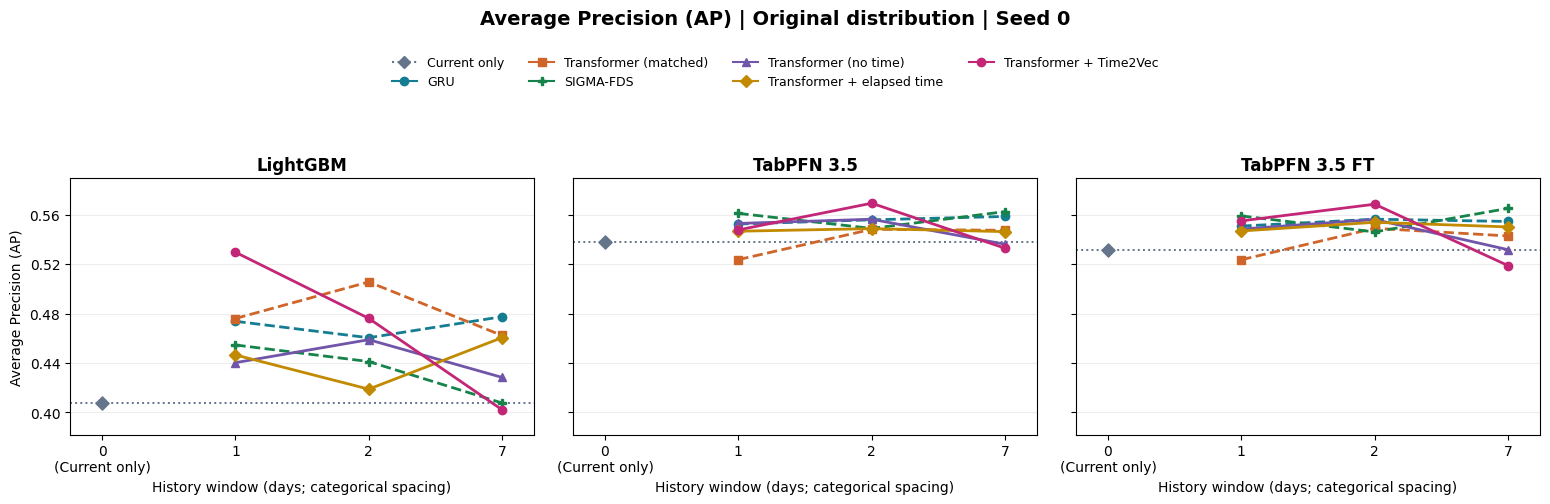

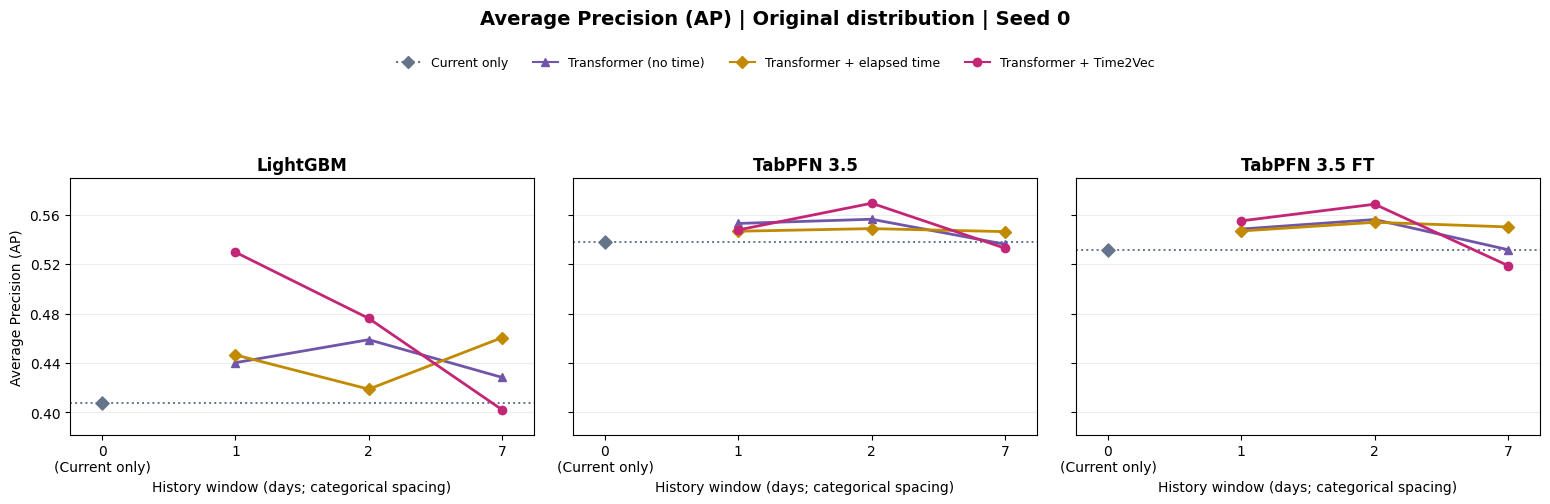

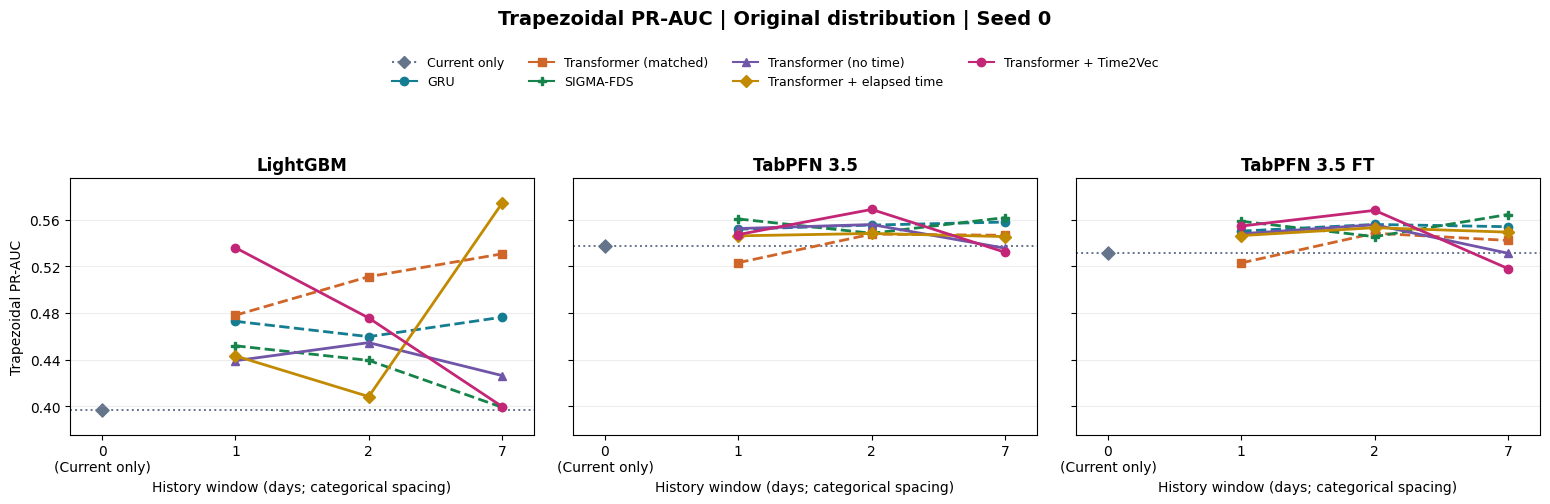

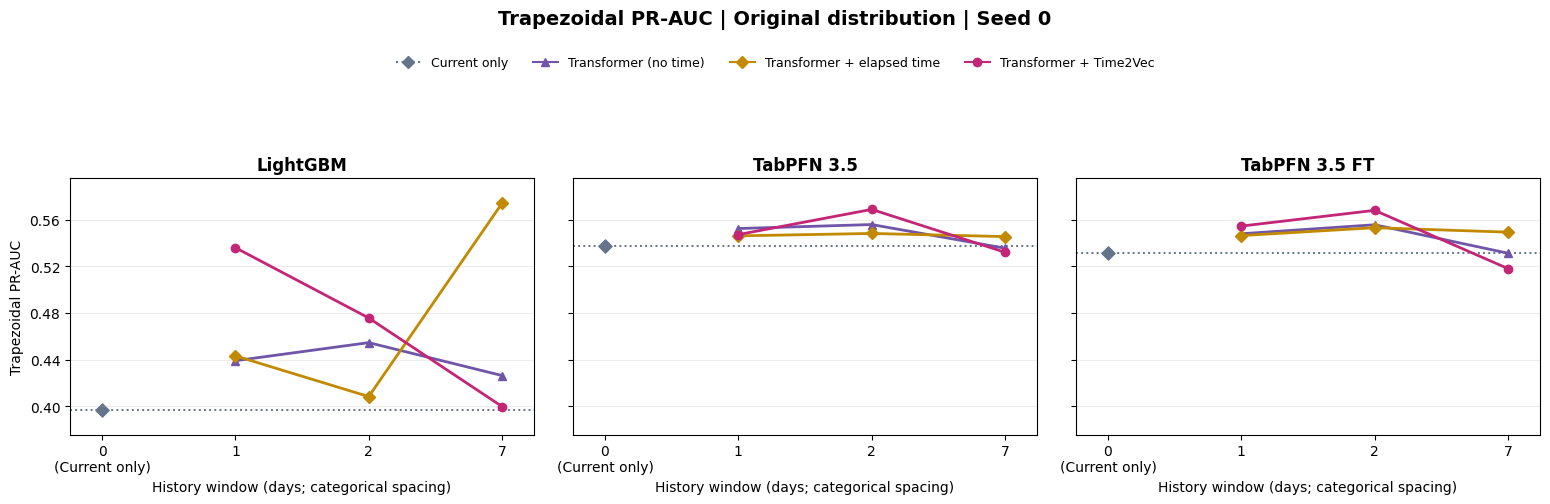

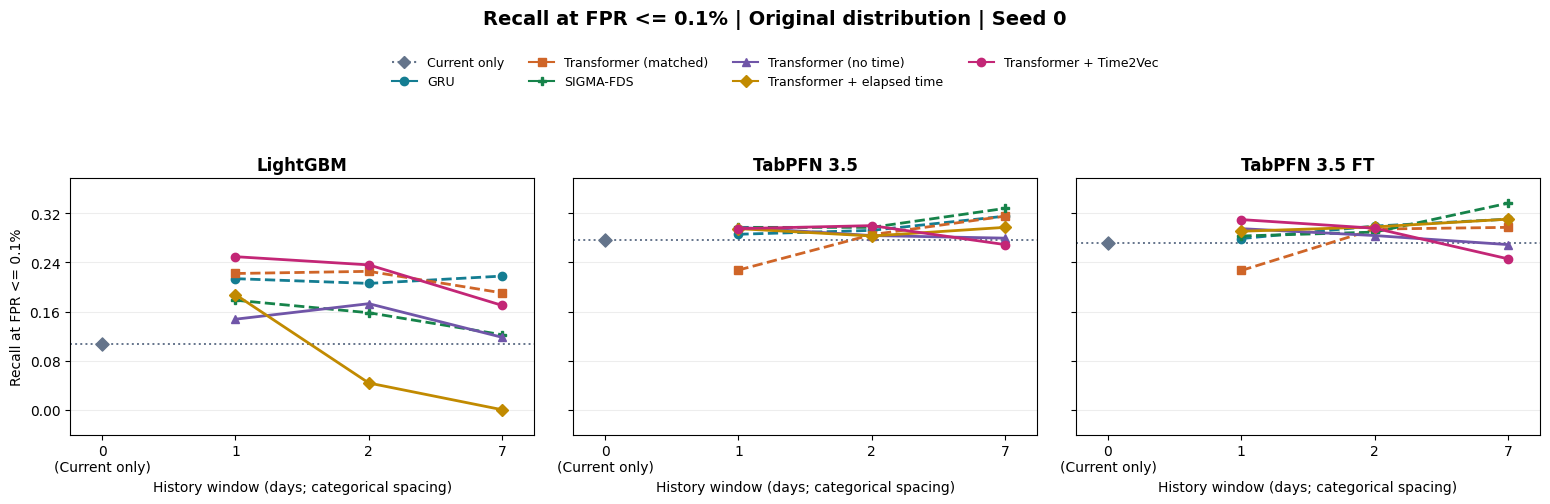

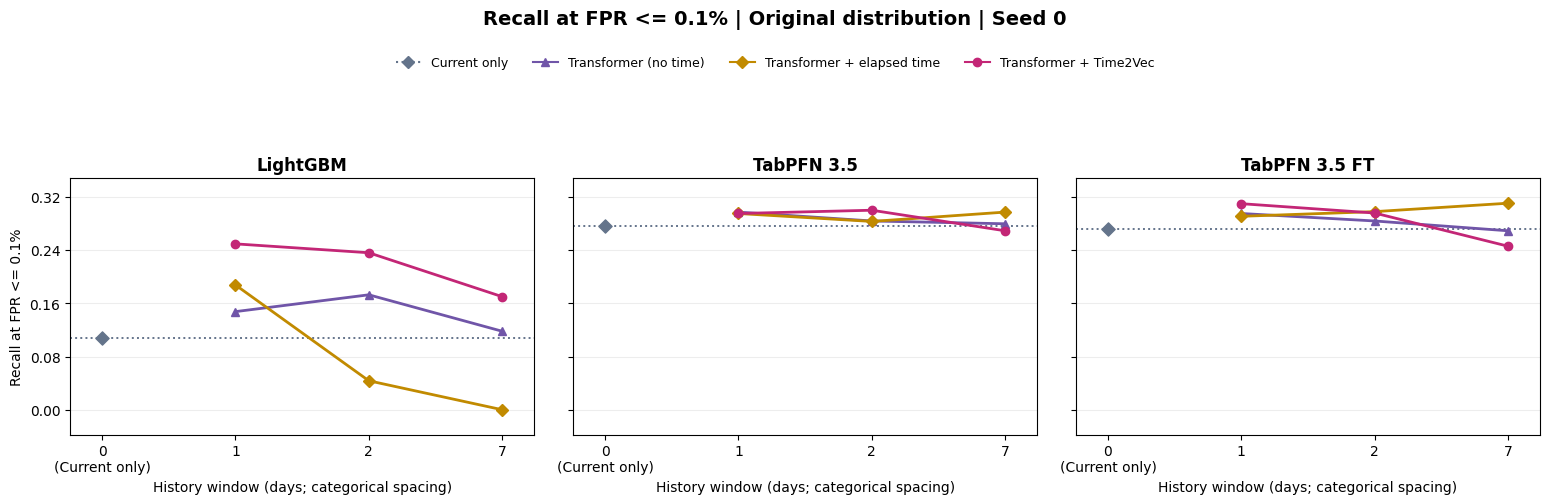

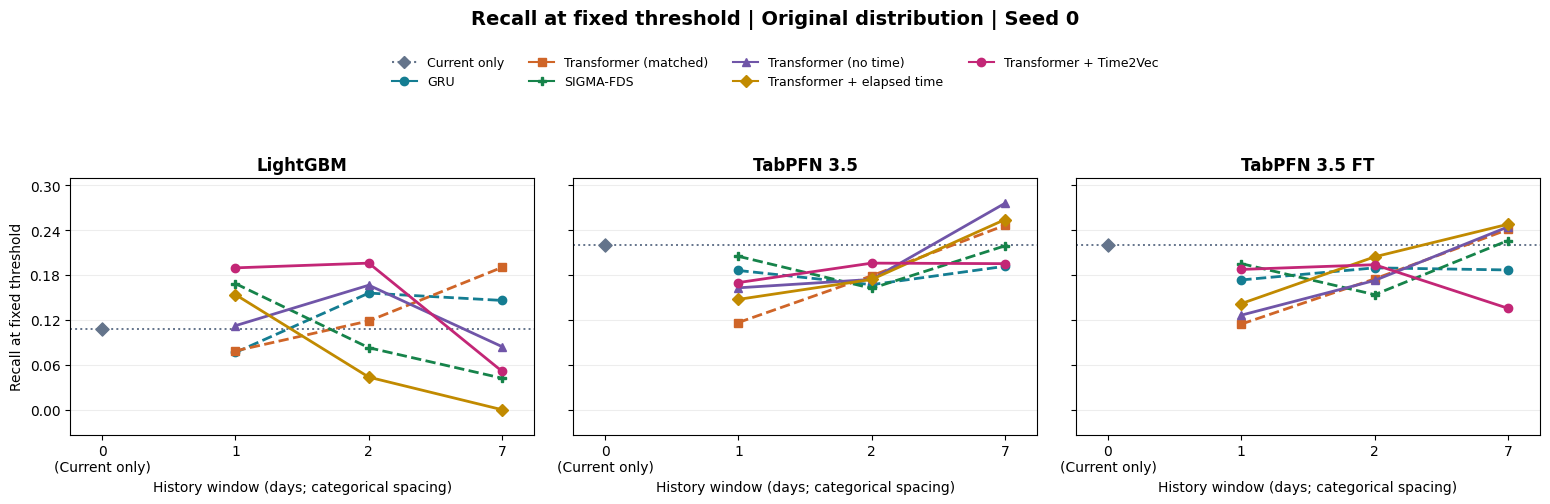

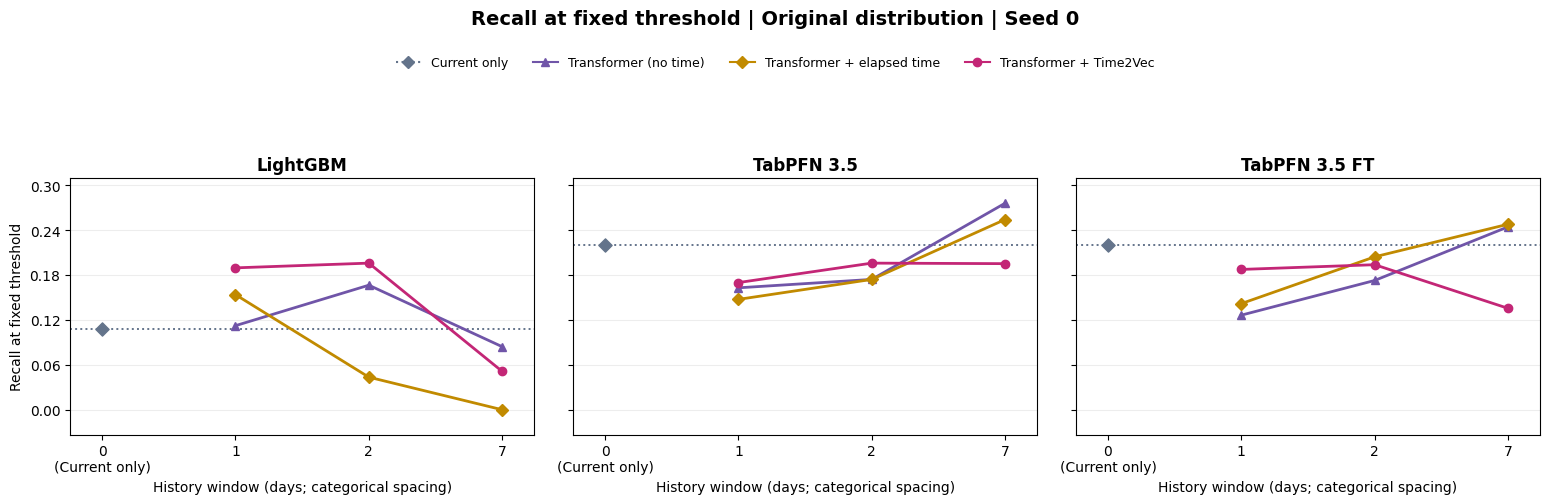

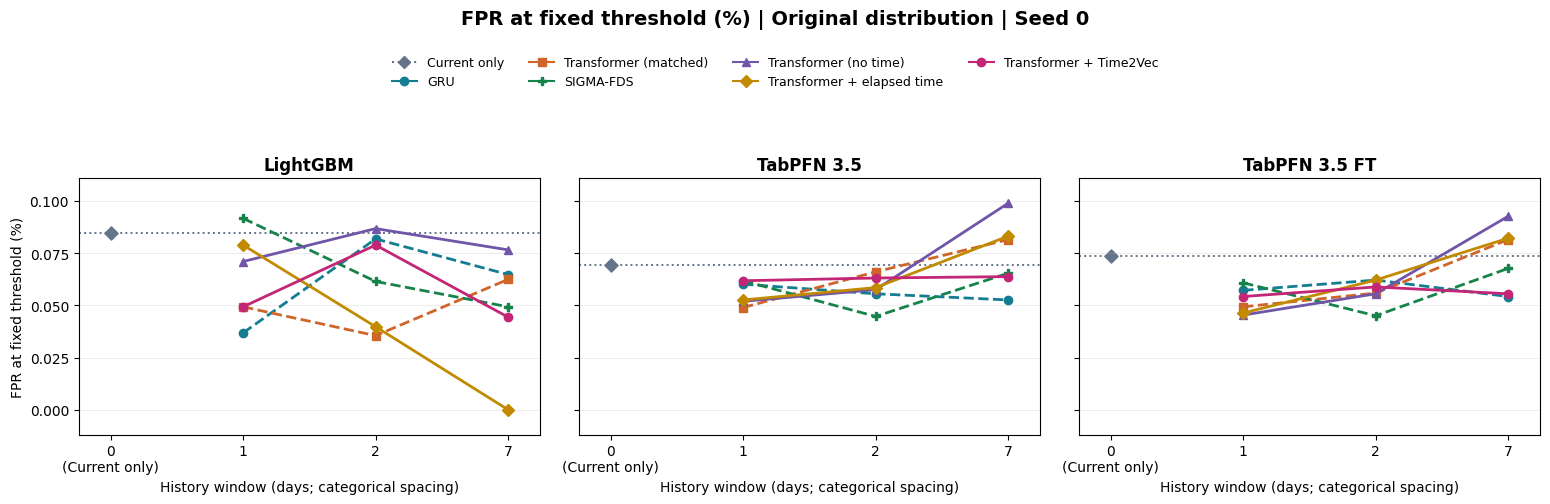

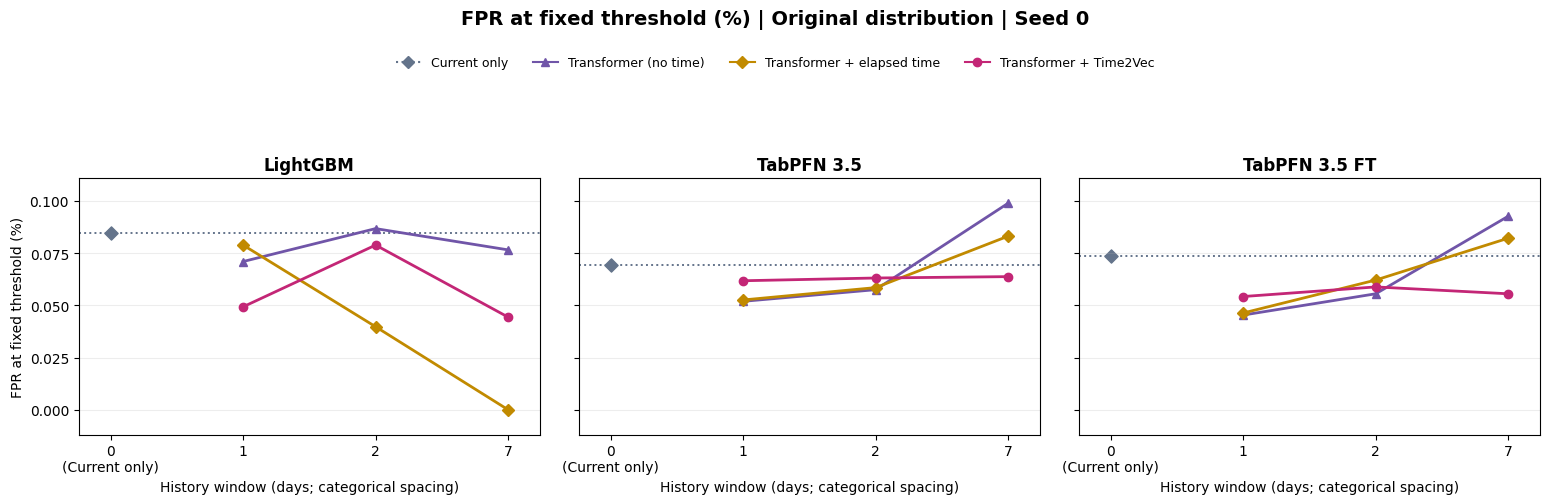

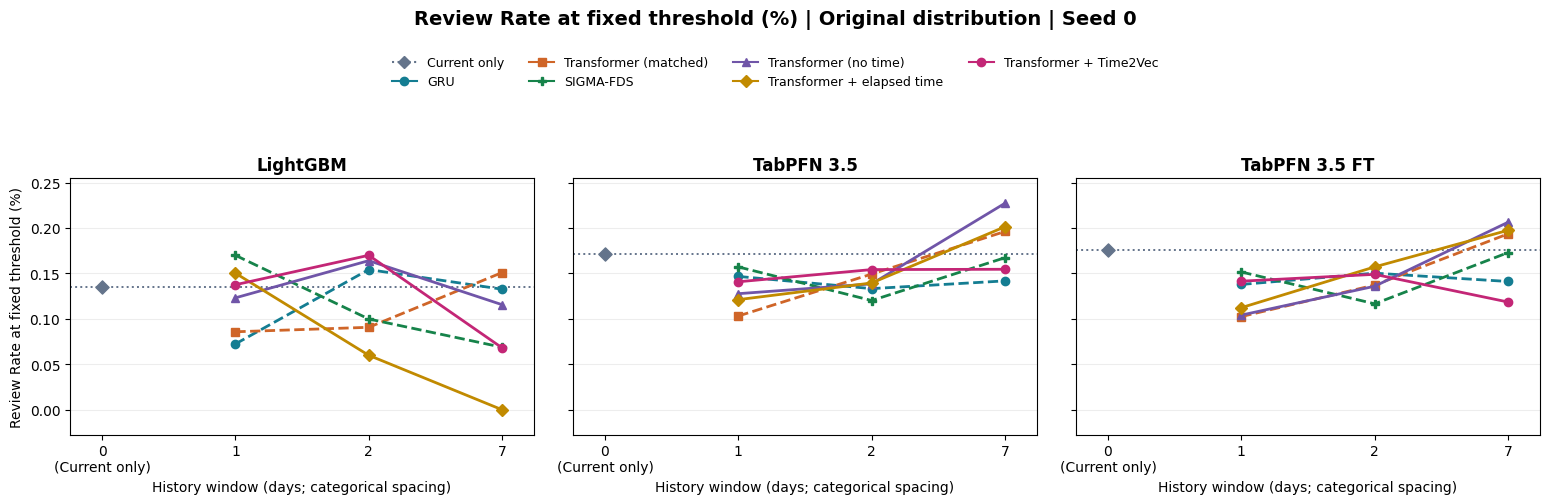

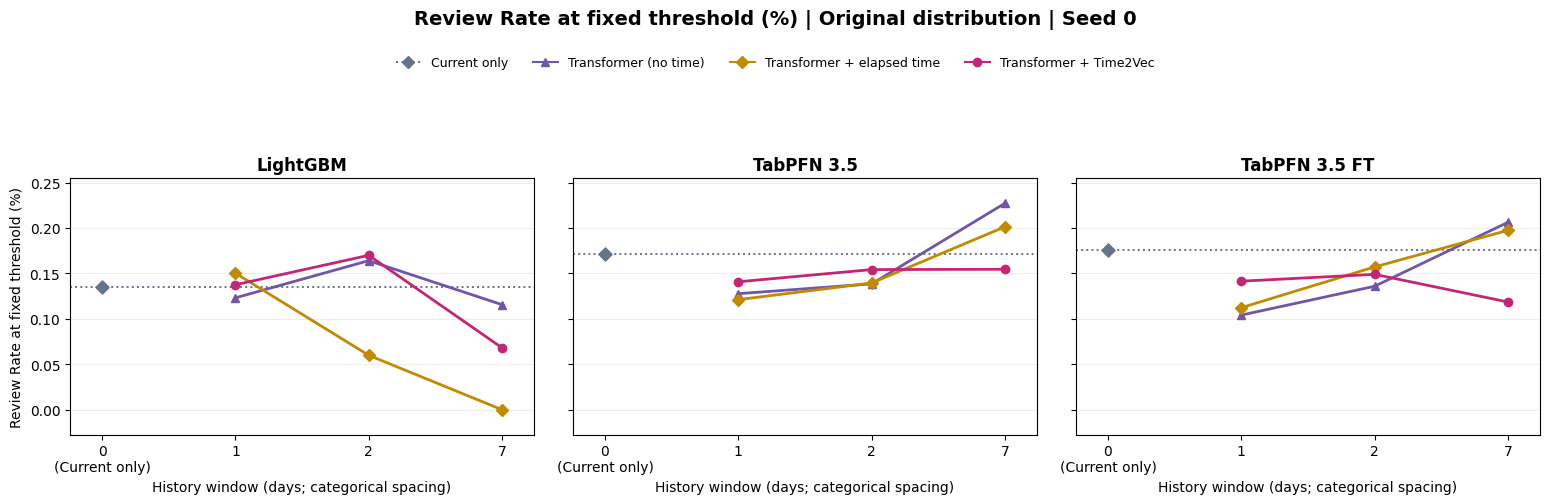

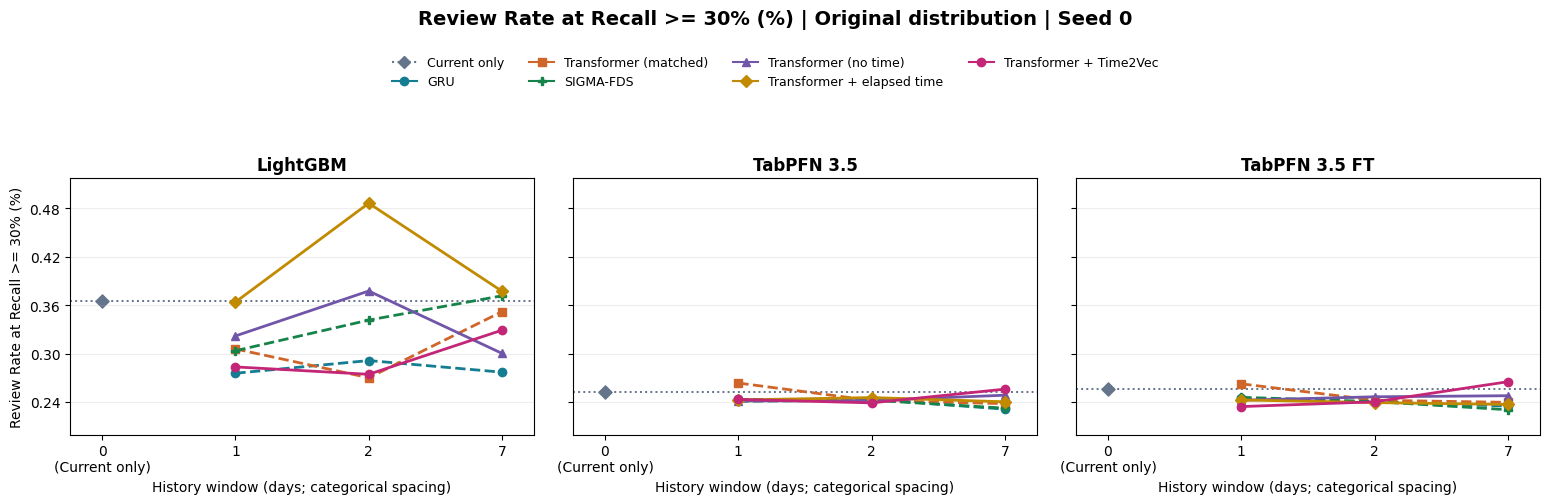

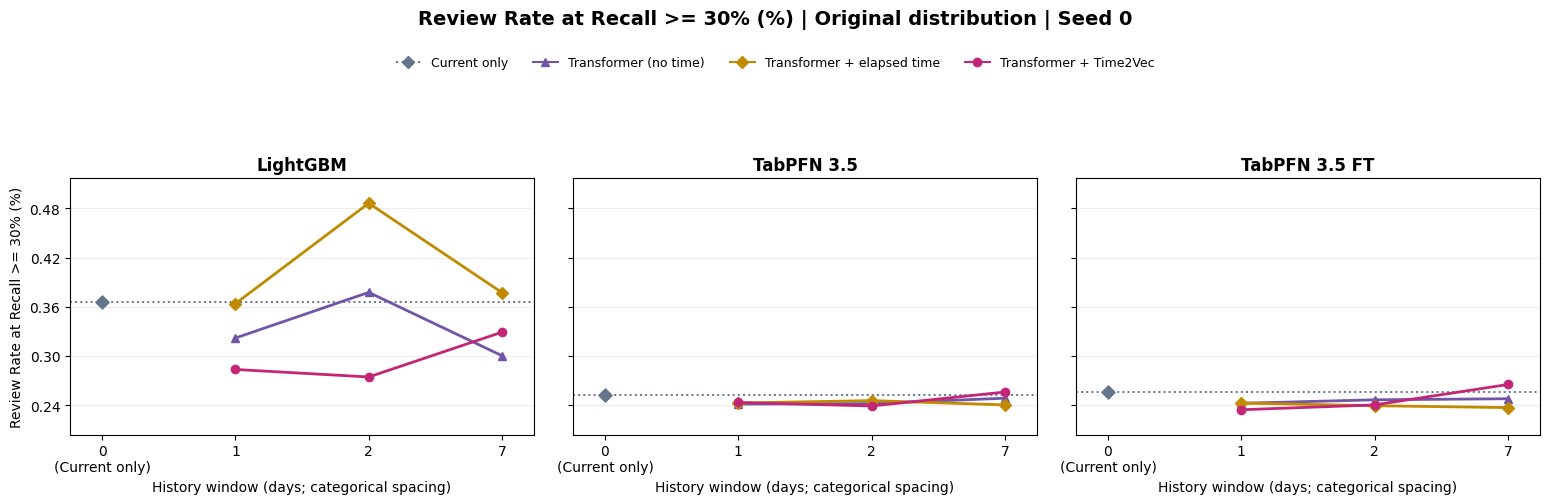

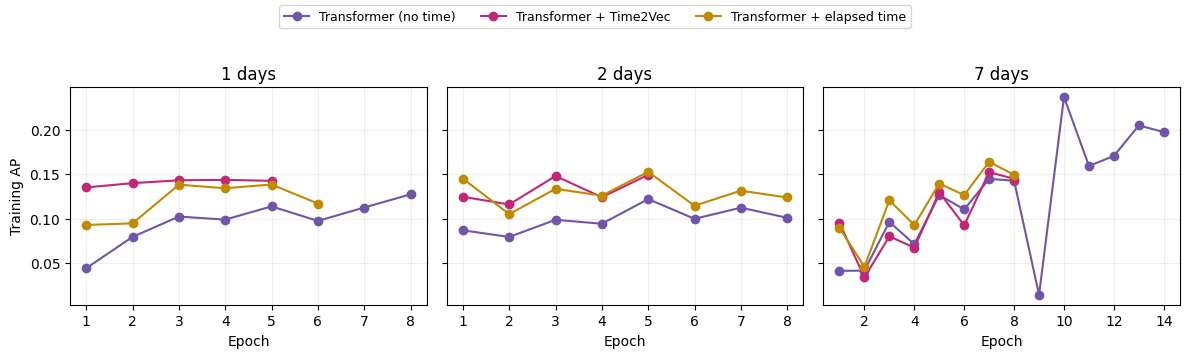

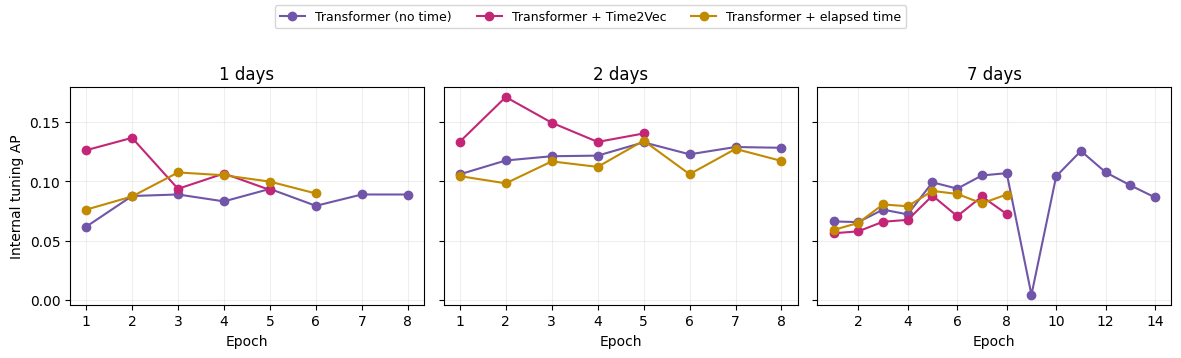

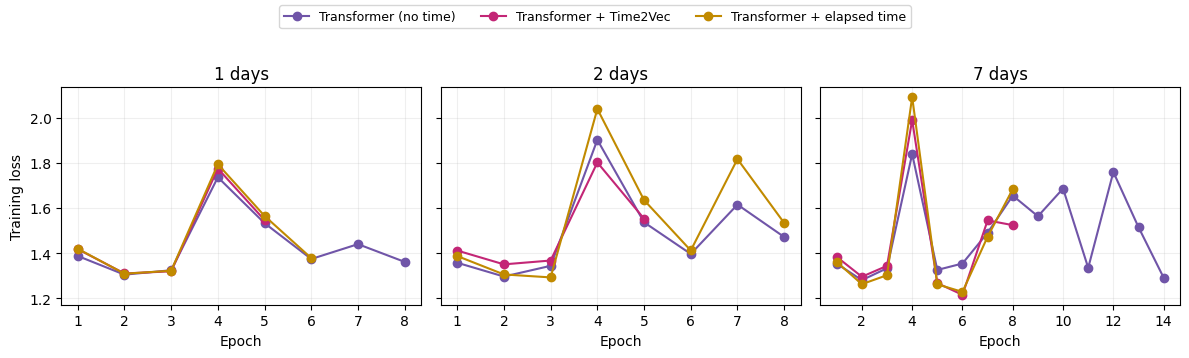

Saved: /content/drive/MyDrive/26-2_AI_project/processed/full/timeaware_transformer_ablation_tabpfn35_original_seed0_v1_full/pilot_seed0/short_1_2_7


In [10]:
# Report function: use complete selected windows only. Never fill missing metrics.
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D

def report(days,tag):
    folder=PILOT/tag; folder.mkdir(exist_ok=True)
    frames=[]; hist=[]
    for arm,label in ARMS.items():
        activate_arm(arm); r=collect()
        r=r[r.days.isin(days)].copy()
        assert len(r)==len(days)*len(MODELS)*len(RUN_SEEDS) and not r.duplicated(['days','seed','model']).any()
        assert set(r.history_encoder)=={label} and set(r.encoder_parameters)=={PARAMS[arm]}
        r['encoder_train_sec']=r['transformer_train_sec']; r['encoder_tune_AP']=r['transformer_tune_AP']; frames.append(r)
        for d in days:
            info=json.loads((OUT/'embeddings'/f'd{d}_s0.json').read_text())
            hist.extend(dict(arm=label,days=d,seed=0,**h) for h in info['history'])
    res=pd.concat(frames,ignore_index=True)
    ref=reference[reference.days.isin([0]+days)]
    allres=pd.concat([ref,res],ignore_index=True).sort_values(['model','days','history_encoder'])
    write_csv(folder/'comparison_all_encoders_seed0.csv',allres)
    cols=['history_encoder','days','model','encoder_parameters','encoder_tune_AP','AP','PR_AUC','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed','review_rate_at_target_recall']
    display(allres[cols].round(5))
    metrics_spec=[('AP','Average Precision (AP)'),('PR_AUC','Trapezoidal PR-AUC'),('Recall_at_FPR','Recall at FPR <= 0.1%'),('fixed_recall','Recall at fixed threshold'),('fixed_fpr','FPR at fixed threshold (%)'),('review_rate_fixed','Review Rate at fixed threshold (%)'),('review_rate_at_target_recall','Review Rate at Recall >= 30% (%)')]
    keys=['seed','days','model']; mk=[k for k,_ in metrics_spec]
    ctrl=res[res.time_arm.eq('none')][keys+mk]
    scalar=res[res.time_arm.eq('scalar')][keys+mk]
    paired=res[res.time_arm.ne('none')].merge(ctrl.rename(columns={k:k+'_control' for k in mk}),on=keys,validate='many_to_one').merge(scalar.rename(columns={k:k+'_scalar' for k in mk}),on=keys,validate='many_to_one')
    for k in mk:
        paired[k+'_vs_control_pp']=100*(paired[k]-paired[k+'_control'])
        paired[k+'_vs_scalar_pp']=100*(paired[k]-paired[k+'_scalar'])
    write_csv(folder/'paired_temporal_deltas_seed0.csv',paired)
    display(paired[['history_encoder','days','model','AP_vs_control_pp','AP_vs_scalar_pp','Recall_at_FPR_vs_control_pp','review_rate_at_target_recall_vs_control_pp']].round(4))
    palette={'Current transaction only':'#64748b','GRU':'#147d92','Transformer (matched)':'#cf6528','SIGMA-FDS':'#16834a',ARMS['none']:'#7055a8',ARMS['scalar']:'#c18a00',ARMS['time2vec']:'#c32676'}
    styles={'GRU':'o--','Transformer (matched)':'s--','SIGMA-FDS':'P--',ARMS['none']:'^-',ARMS['scalar']:'D-',ARMS['time2vec']:'o-'}
    styles={k:v for k,v in styles.items() if k in set(allres.history_encoder)}
    windows=[0]+days; pos={d:i for i,d in enumerate(windows)}
    for k,title in metrics_spec:
        factor=100 if k.startswith('review_rate') or k=='fixed_fpr' else 1
        for scope,selected in [('all',list(styles)),('ablation',list(ARMS.values()))]:
            fig,axes=plt.subplots(1,3,figsize=(15.6,5.1),sharey=True)
            for ax,m in zip(axes,MODELS):
                b=allres[(allres.model==m)&(allres.history_encoder=='Current transaction only')]
                bv=float(b[k].iloc[0])*factor
                ax.axhline(bv,color=palette['Current transaction only'],ls=':',lw=1.4)
                ax.scatter(0,bv,marker='D',s=45,color=palette['Current transaction only'])
                for enc in selected:
                    g=allres[(allres.model==m)&(allres.history_encoder==enc)].sort_values('days')
                    ax.plot([pos[d] for d in g.days],g[k]*factor,styles[enc],color=palette[enc],lw=2,ms=6,label=enc)
                ax.set_title(m,fontweight='bold'); ax.set_xticks(range(len(windows)),['0\n(Current only)']+[str(d) for d in days]); ax.set_xlabel('History window (days; categorical spacing)'); ax.grid(axis='y',alpha=.22); ax.margins(x=.08,y=.12); ax.yaxis.set_major_locator(MaxNLocator(6))
            axes[0].set_ylabel(title)
            handles=[Line2D([0],[0],color=palette['Current transaction only'],ls=':',marker='D',label='Current only')]+[Line2D([0],[0],color=palette[e],marker=styles[e][0],label=e) for e in selected]
            fig.suptitle(title+' | Original distribution | Seed 0',fontsize=14,fontweight='bold',y=.98)
            fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,.91),ncol=4,frameon=False,fontsize=9)
            fig.tight_layout(rect=[0,0,1,.79]); fig.savefig(folder/f'{scope}_{k}.png',dpi=220,bbox_inches='tight'); fig.savefig(folder/f'{scope}_{k}.svg',bbox_inches='tight'); plt.show(); plt.close(fig)
    h=pd.DataFrame(hist); write_csv(folder/'encoder_history.csv',h)
    for k,title in [('fit_AP','Training AP'),('tune_AP','Internal tuning AP'),('loss','Training loss')]:
        fig,axes=plt.subplots(1,len(days),figsize=(4*len(days),3.6),sharey=True,squeeze=False)
        for ax,d in zip(axes[0],days):
            for enc,g in h[h.days.eq(d)].groupby('arm'):
                ax.plot(g.epoch,g[k],marker='o',label=enc,color=palette[enc])
            ax.set_title(f'{d} days'); ax.set_xlabel('Epoch'); ax.grid(alpha=.2)
        axes[0,0].set_ylabel(title); handles,labels=axes[0,0].get_legend_handles_labels(); fig.legend(handles,labels,loc='upper center',ncol=3,fontsize=9); fig.tight_layout(rect=[0,0,1,.87]); fig.savefig(folder/f'encoder_{k}.png',dpi=180,bbox_inches='tight'); plt.show(); plt.close(fig)
    write_csv(folder/'timing_with_hardware.csv',allres[[k for k in ['history_encoder','days','model','session','gpu','cpu','encoder_train_sec','embedding_sec','classifier_fit_sec','offline_eval_sec','calibration_sec','p95_ms'] if k in allres]])
    print('Saved:',folder)

report(SHORT_DAYS,'short_1_2_7')


Transformer (no time) | Phase: 0/6 (0.0%)
=== 14 days / seed 0 / remaining ['LightGBM', 'TabPFN 3.5', 'TabPFN 3.5 FT'] ===
Transformer (no time) d=14 seed=0 epoch=1/20 loss=1.32397 tune_AP=0.06297 fit_AP=0.05020
Transformer (no time) d=14 seed=0 epoch=2/20 loss=1.21240 tune_AP=0.07003 fit_AP=0.08119
Transformer (no time) d=14 seed=0 epoch=3/20 loss=1.36701 tune_AP=0.10974 fit_AP=0.12638
Transformer (no time) d=14 seed=0 epoch=4/20 loss=1.88780 tune_AP=0.10967 fit_AP=0.13983
Transformer (no time) d=14 seed=0 epoch=5/20 loss=1.37672 tune_AP=0.12049 fit_AP=0.15781
Transformer (no time) d=14 seed=0 epoch=6/20 loss=1.40428 tune_AP=0.11846 fit_AP=0.19172
Transformer (no time) d=14 seed=0 epoch=7/20 loss=1.48636 tune_AP=0.12281 fit_AP=0.15664
Transformer (no time) d=14 seed=0 epoch=8/20 loss=1.35604 tune_AP=0.12900 fit_AP=0.18425
Transformer (no time) d=14 seed=0 epoch=9/20 loss=1.62637 tune_AP=0.21778 fit_AP=0.12232
Transformer (no time) d=14 seed=0 epoch=10/20 loss=1.69913 tune_AP=0.11313 f

/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_classifier.py:175: UserWarning: `use_fixed_preprocessing_seed` should only be used if `n_estimators_finetune` == `n_estimators_validation` == `n_estimators_final_inference`. Consider setting the number of estimators for validation and final inference to the same value as `n_estimators_finetune`(=1).
  super().__init__(
/usr/local/lib/python3.13/dist-packages/tabpfn/finetuning/finetuned_classifier.py:424: UserWarning: `output_dir` is not set. This means no checkpointing will be done and all progress will be lost if the training is interrupted.
  super().fit(X, y, X_val=X_val, y_val=y_val, output_dir=output_dir)


Finetuning Epoch 1/10:   0%|          | 0/2 [00:00<?, ?it/s]

Finetuning Epoch 2/10:   0%|          | 0/2 [00:00<?, ?it/s]

Finetuning Epoch 3/10:   0%|          | 0/2 [00:00<?, ?it/s]

Prediction (305,365 rows):   0%|          | 0/75 [00:00<?, ?it/s]

... (82 outputs left out)

Prediction (50,926 rows):   0%|          | 0/13 [00:00<?, ?it/s]

TabPFN 3.5 FT 30d seed=0: AP=0.5692, Recall=0.3212, Review=0.1362%, P95=731.020ms (15/15)
Transformer + Time2Vec | Phase: 6/6 (100.0%)
Transformer + Time2Vec | Phase: 6/6 (100.0%)


,history_encoder,days,model,encoder_parameters,encoder_tune_AP,AP,PR_AUC,Recall_at_FPR,fixed_recall,fixed_fpr,review_rate_fixed,review_rate_at_target_recall
0,Current transaction only,0,LightGBM,0,0.00000,0.40747,0.39703,0.10752,0.10752,0.00085,0.00135,0.00365
3,GRU,1,LightGBM,3969,0.04064,0.47370,0.47280,0.21363,0.07660,0.00037,0.00072,0.00276
33,SIGMA-FDS,1,LightGBM,132612,0.02660,0.45457,0.45184,0.17850,0.16866,0.00092,0.00170,0.00304
18,Transformer (matched),1,LightGBM,3957,0.09673,0.47595,0.47802,0.22207,0.07871,0.00049,0.00086,0.00306
50,Transformer (no time),1,LightGBM,8833,0.09358,0.44026,0.43904,0.14758,0.11244,0.00071,0.00123,0.00322
...,...,...,...,...,...,...,...,...,...,...,...,...
47,SIGMA-FDS,30,TabPFN 3.5 FT,132612,0.05846,0.56389,0.56324,0.32537,0.21012,0.00047,0.00144,0.00223
32,Transformer (matched),30,TabPFN 3.5 FT,3957,0.45352,0.60894,0.60858,0.36402,0.24455,0.00048,0.00162,0.00205
62,Transformer (no time),30,TabPFN 3.5 FT,8833,0.44905,0.55484,0.55421,0.30218,0.22699,0.00068,0.00174,0.00239
92,Transformer + Time2Vec,30,TabPFN 3.5 FT,9137,0.38113,0.56917,0.56866,0.32115,0.19888,0.00044,0.00136,0.00227


,history_encoder,days,model,AP_vs_control_pp,AP_vs_scalar_pp,Recall_at_FPR_vs_control_pp,review_rate_at_target_recall_vs_control_pp
0,Transformer + elapsed time,1,TabPFN 3.5,-0.6289,0.0000,-0.2108,0.0013
1,Transformer + elapsed time,1,TabPFN 3.5 FT,-0.1550,0.0000,-0.4216,0.0003
2,Transformer + elapsed time,1,LightGBM,0.6264,0.0000,4.0056,0.0419
3,Transformer + elapsed time,2,TabPFN 3.5 FT,-0.2245,0.0000,1.4055,-0.0072
4,Transformer + elapsed time,2,LightGBM,-3.9982,0.0000,-12.9304,0.1087
5,Transformer + elapsed time,2,TabPFN 3.5,-0.7582,0.0000,-0.0703,0.0036
6,Transformer + elapsed time,7,TabPFN 3.5,1.0227,0.0000,1.7569,-0.0082
7,Transformer + elapsed time,7,TabPFN 3.5 FT,1.8407,0.0000,4.1462,-0.0108
8,Transformer + elapsed time,7,LightGBM,3.2142,0.0000,-11.8060,0.0770
9,Transformer + elapsed time,14,TabPFN 3.5 FT,-3.1965,0.0000,-1.4758,0.0033


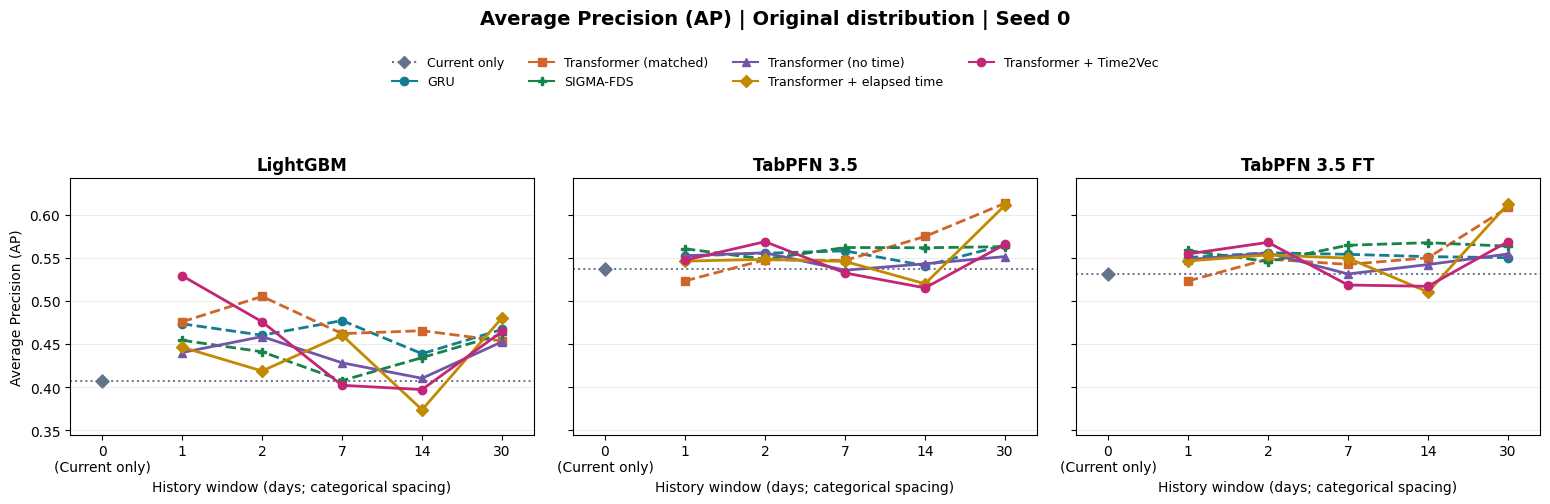

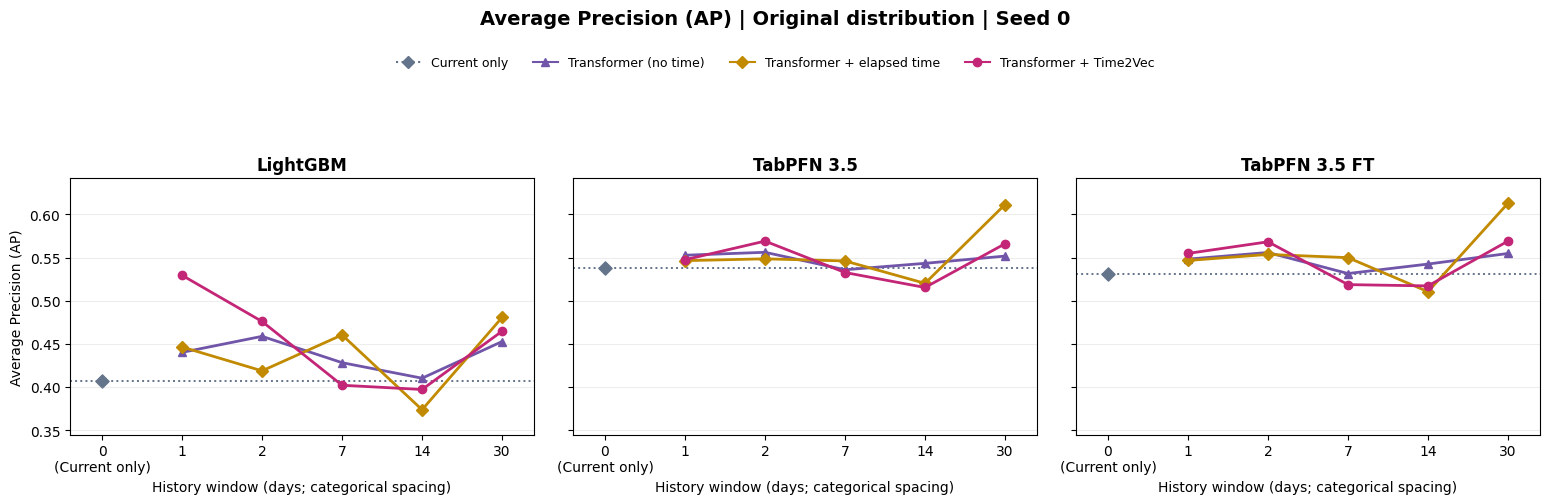

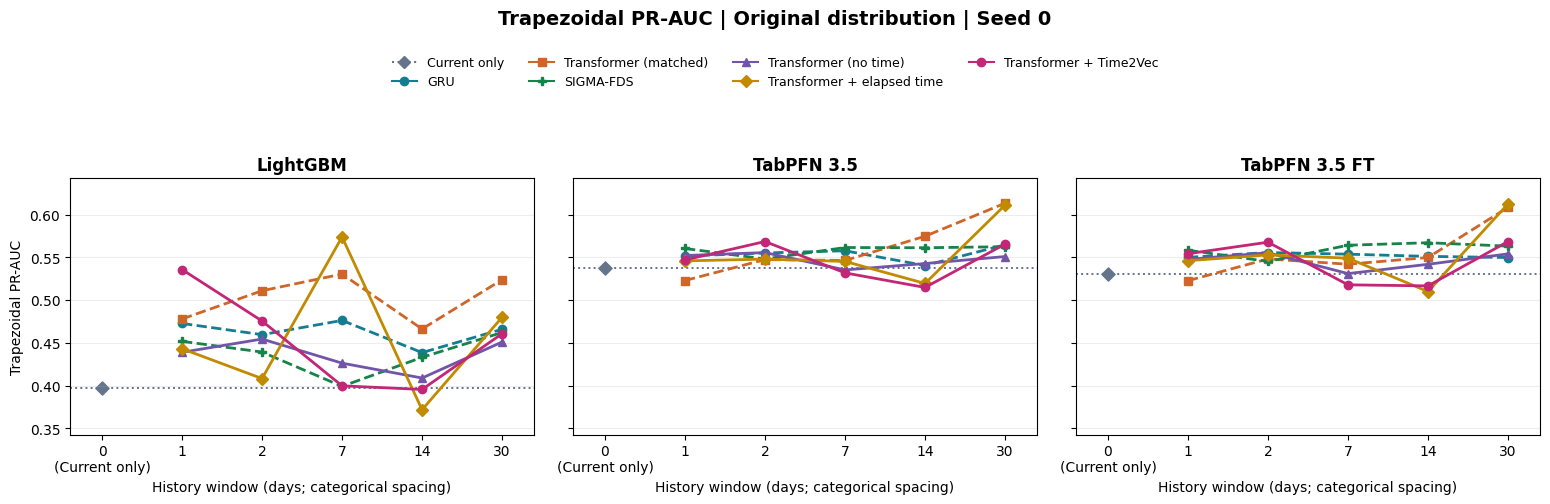

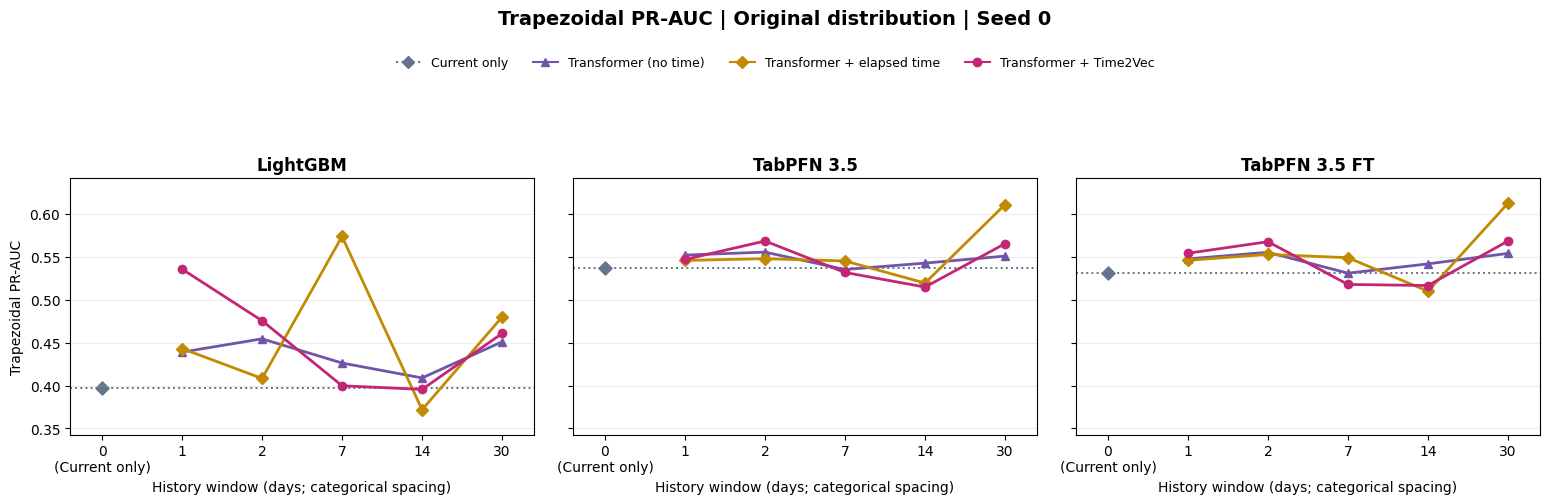

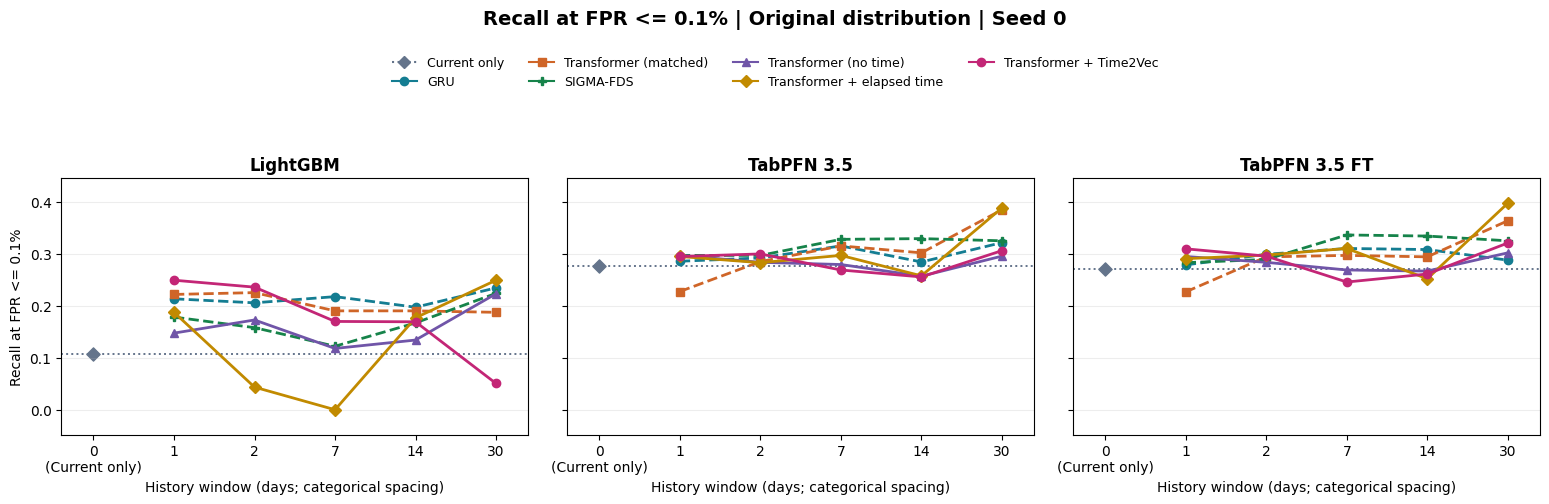

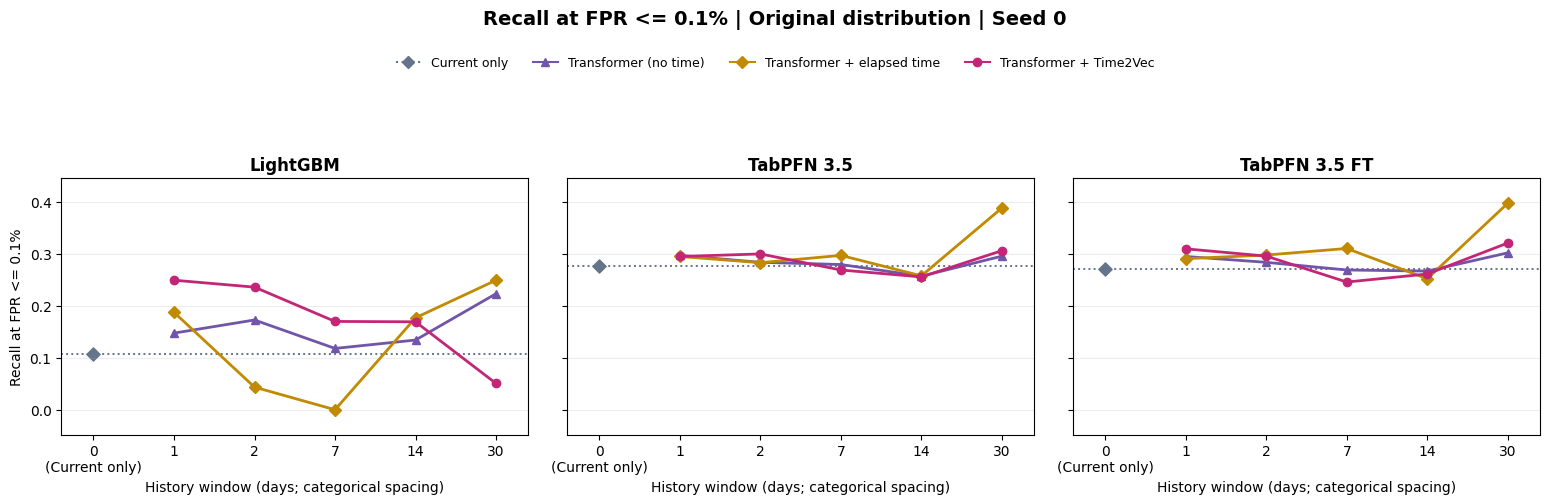

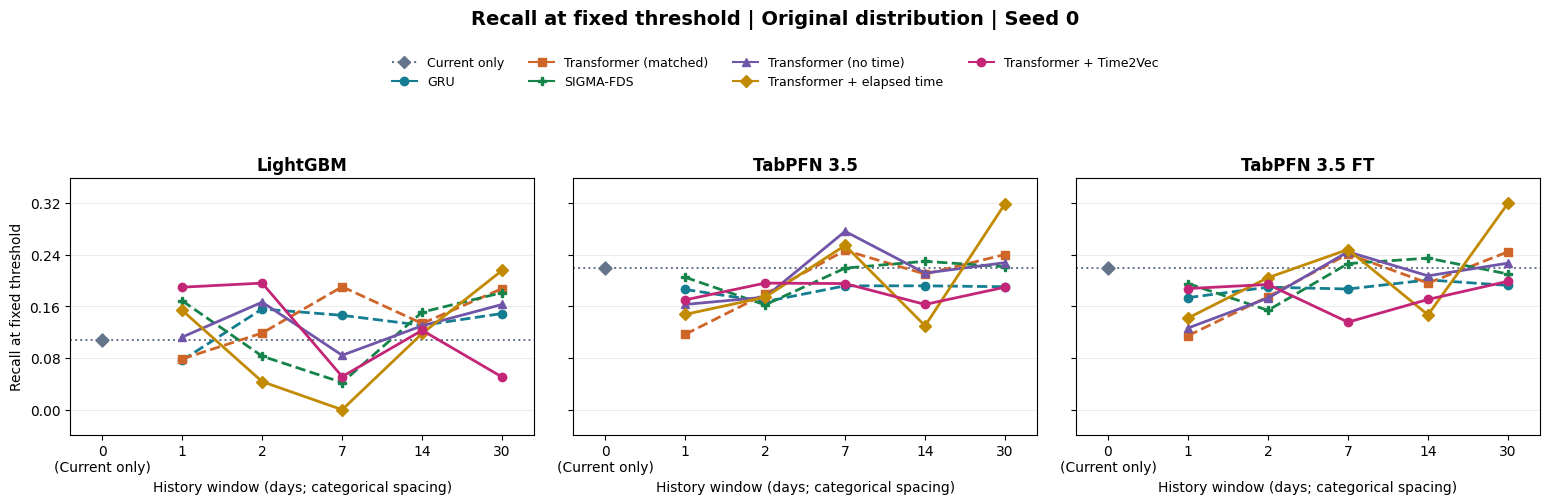

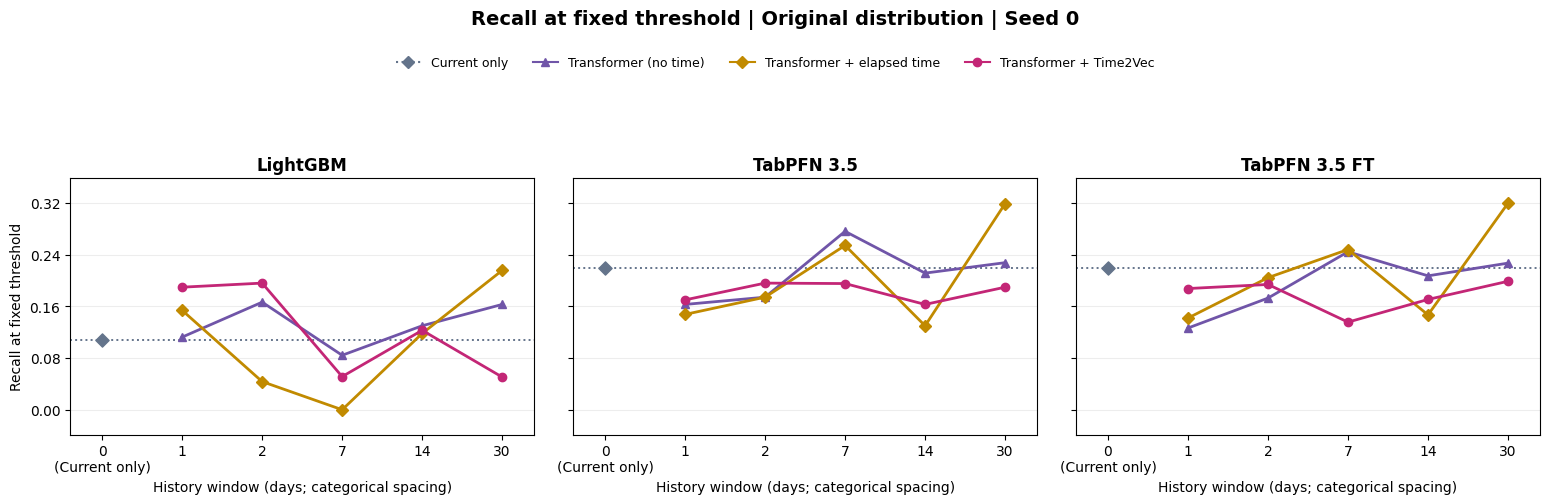

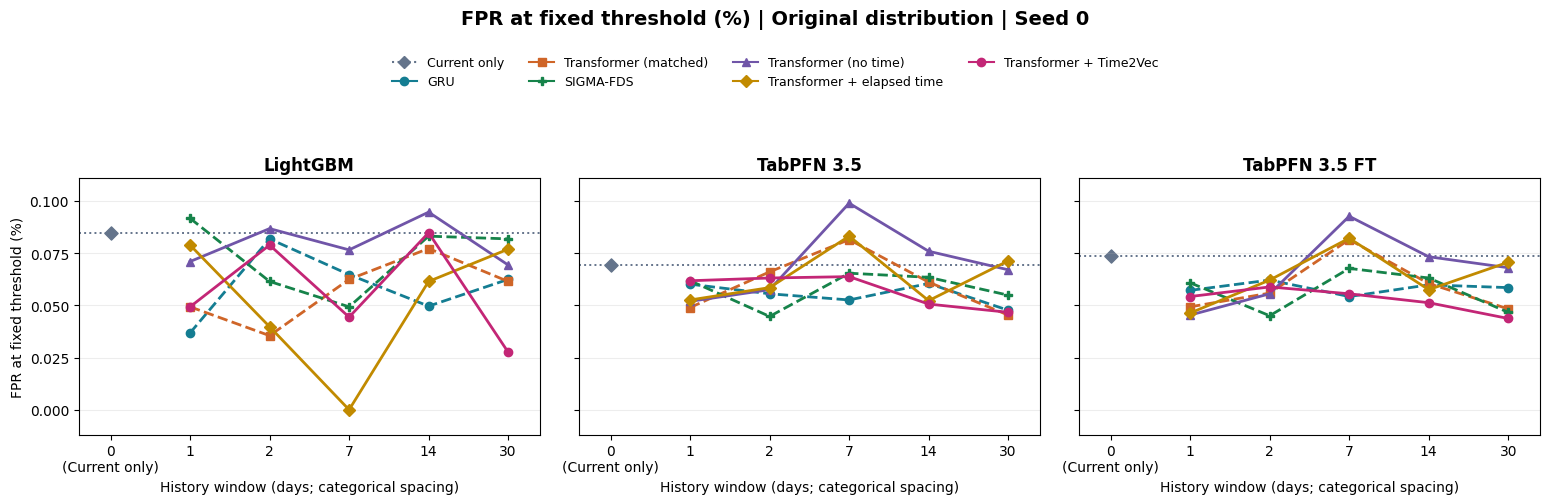

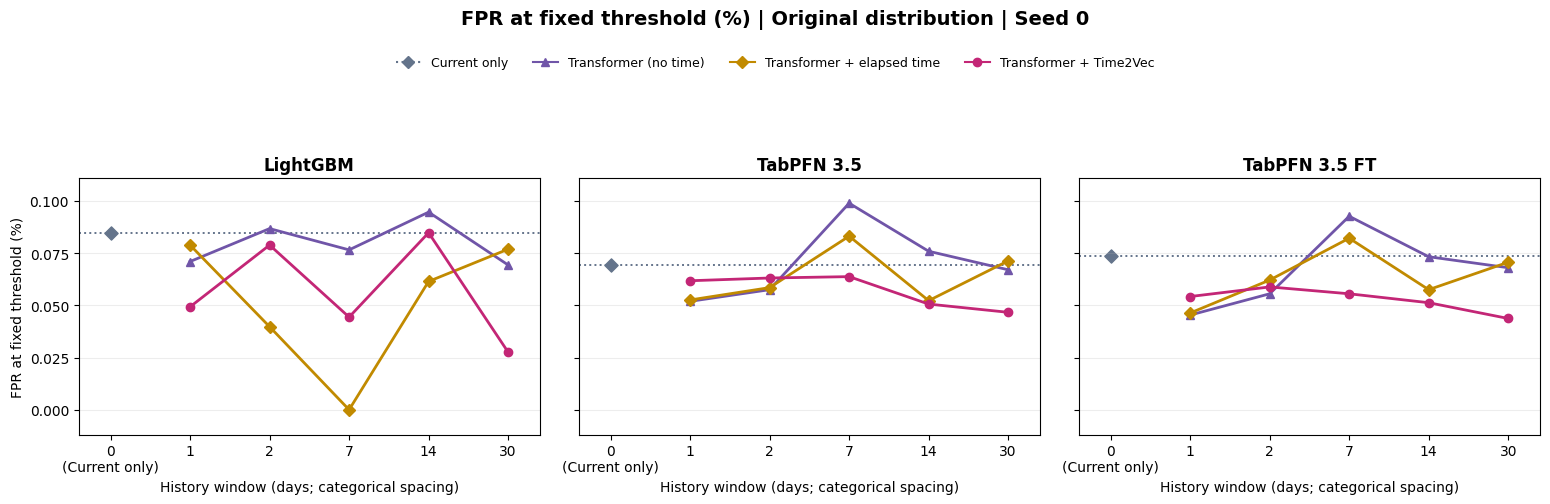

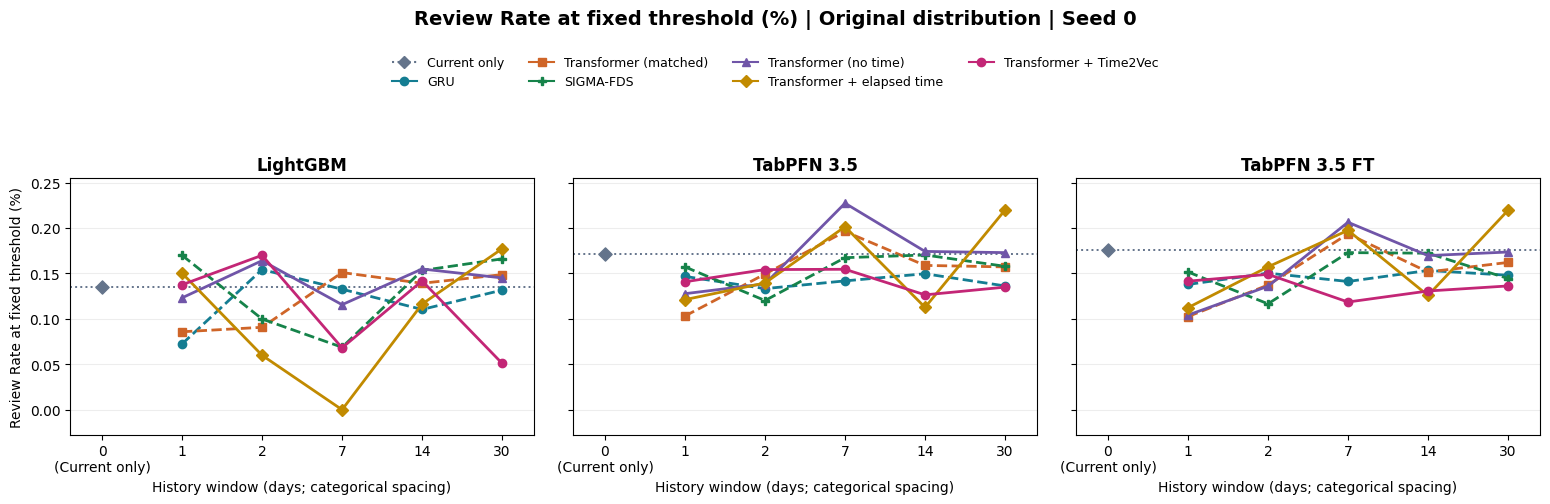

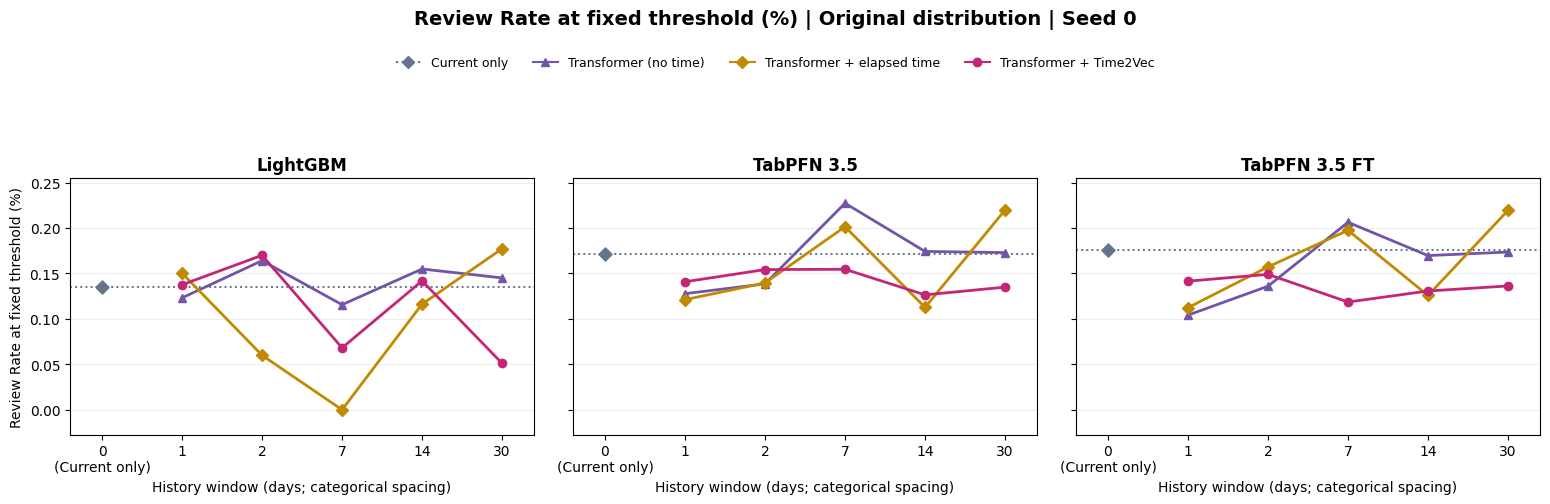

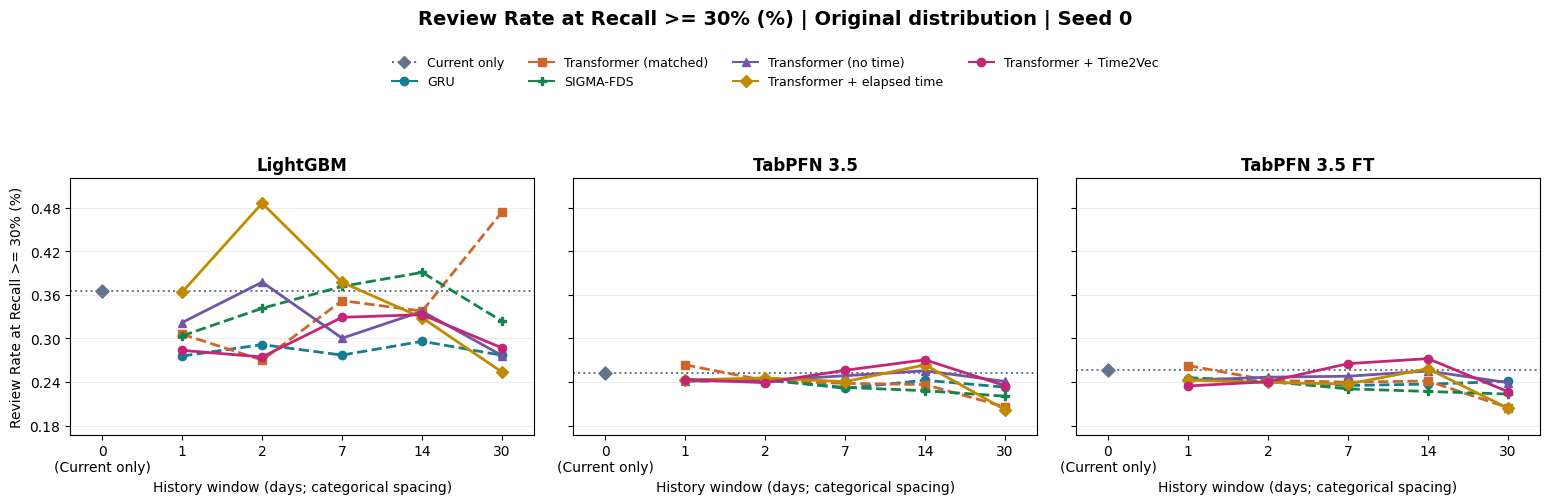

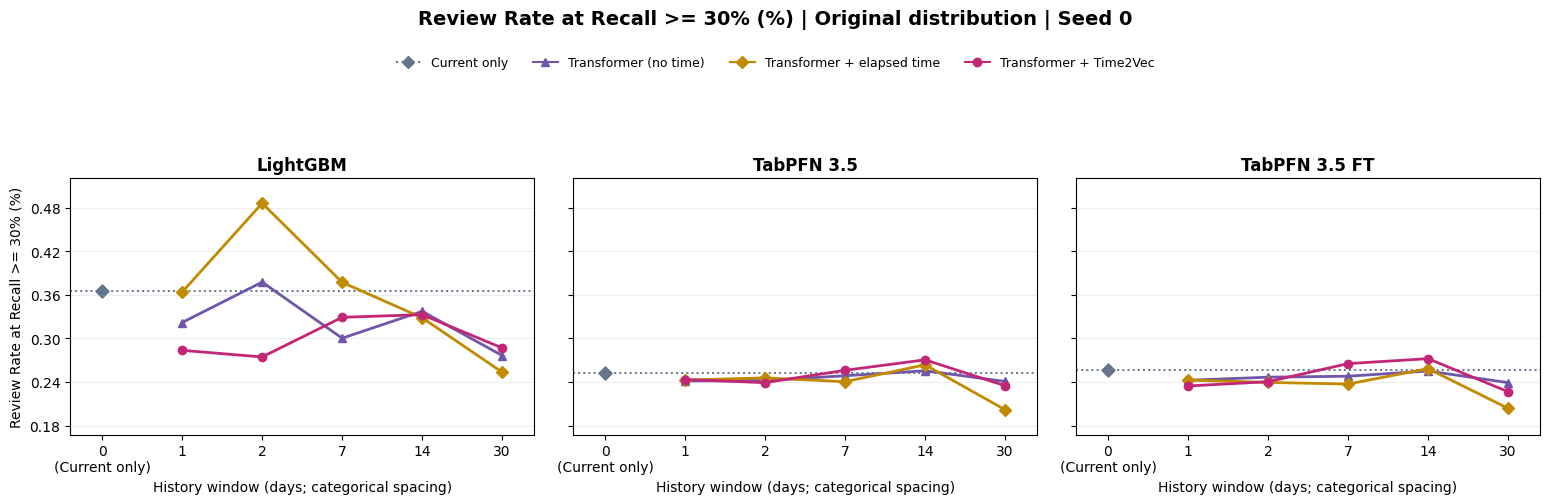

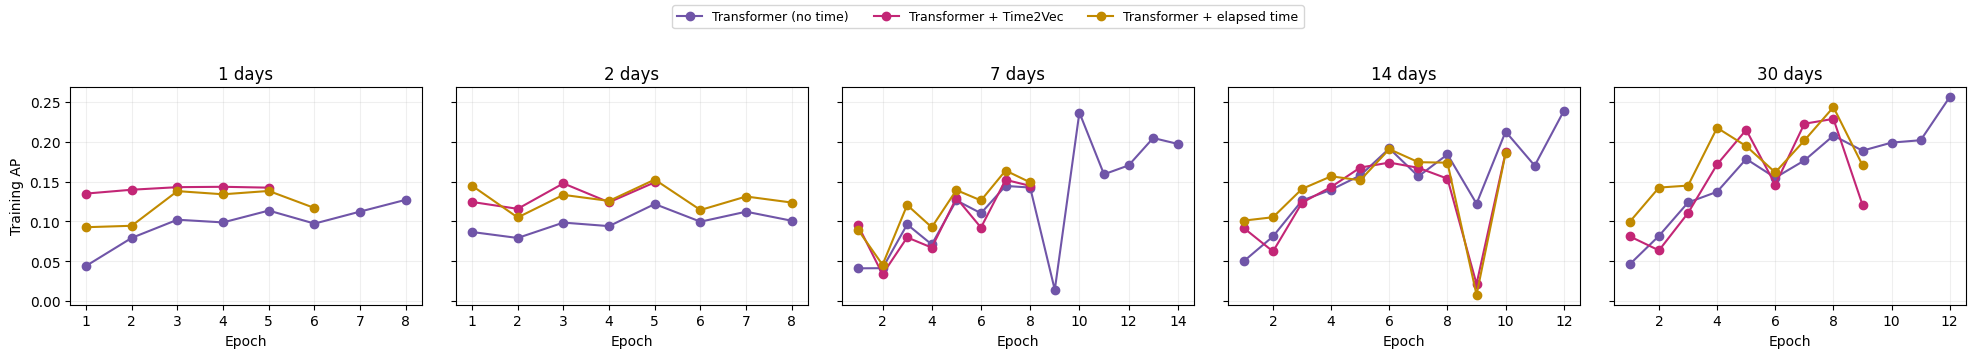

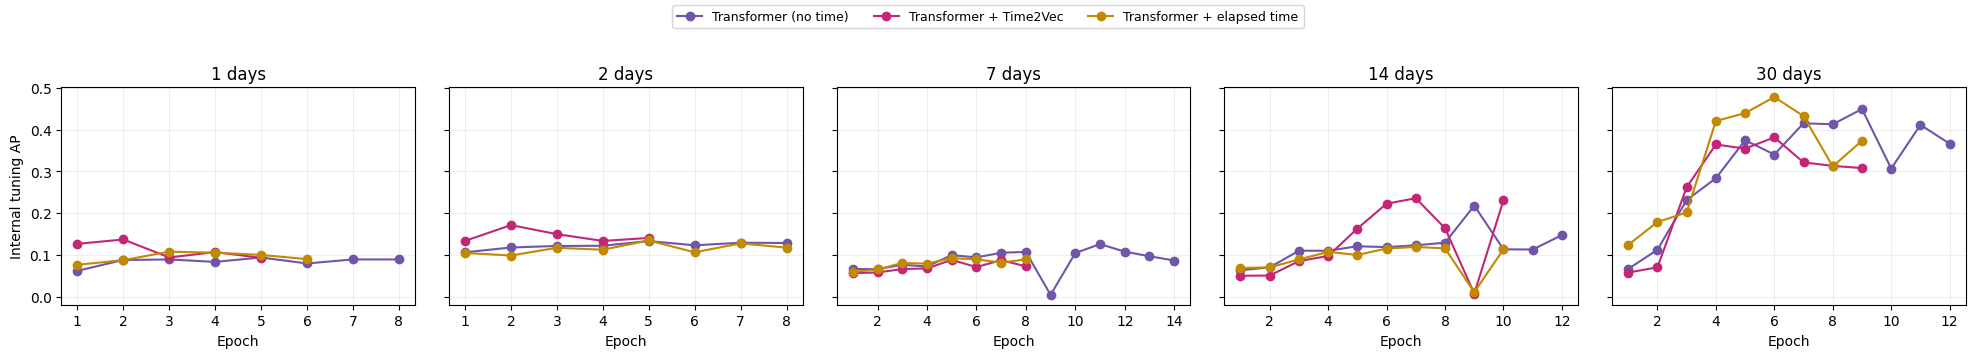

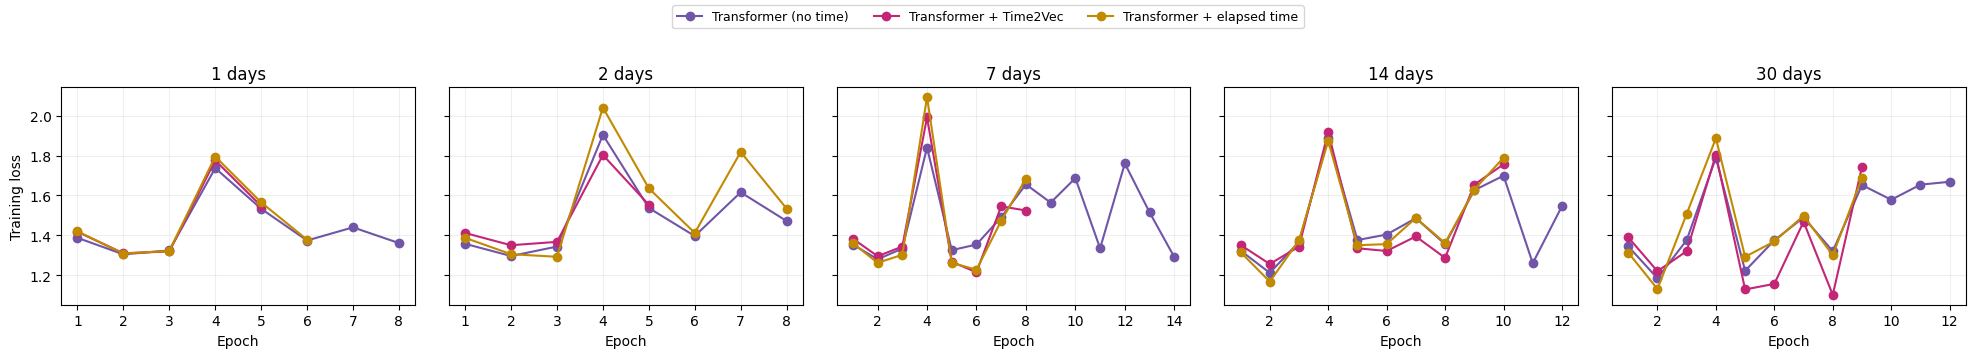

Saved: /content/drive/MyDrive/26-2_AI_project/processed/full/timeaware_transformer_ablation_tabpfn35_original_seed0_v1_full/pilot_seed0/full_1_2_7_14_30


In [11]:
# 11. Optional long-history phase; no changing settings based on short evaluation results.
if RUN_LONG:
    for arm in ARMS:
        activate_arm(arm); run_days(LONG_DAYS,run_seeds=RUN_SEEDS)
    report(RUN_DAYS,'full_1_2_7_14_30')
else:
    print('Long phase deferred. Set RUN_LONG=True and rerun; completed runs are skipped.')


## Interpretation
- Primary comparison is same-backbone no-time vs elapsed vs Time2Vec at 1/2/7 days; 14/30-day results check whether performance is maintained. AP is primary. Recall at evaluation FPR is diagnostic; fixed calibration threshold metrics are operational proxies. Review Rate at matched recall is diagnostic.
- Time2Vec uses normalized log elapsed hours derived from already observed 3-hour bins. It adds no real event timestamps or history outside the selected window. Missing history is marked unknown by zero temporal contribution. Padding policy, data split and label budget unchanged.
- Extra time arms add parameters; not strictly capacity-matched. The direct scalar comparator helps distinguish information versus representation, but does not fully isolate parameter count. No claim of FraudTransformer reproduction or guaranteed improvement. Single seed and only 8 tune positives; verify with additional seeds and untouched Test.
- Model outputs are scores, not necessarily calibrated probabilities. Timing across different hardware is not directly comparable. Classifier weights not saved by existing benchmark pipeline; deployment requires separately preserving/refitting final classifier.
